# `Практикум по программированию на языке Python`

## `Задание 01. Полносвязная нейронная сеть на numpy`.

#### Фамилия, имя: 

Дата выдачи: <span style="color:red">__13 февраля__</span>.

Мягкий дедлайн: <span style="color:red">__28 февраля 05:00__</span>.

Стоимость: __10 баллов__ (основная часть заданий) + __3 балла__ (дополнительные задания).

<span style="color:red">__В ноутбуке все клетки должны выполняться без ошибок при последовательном их выполнении.__</span>

#### `Москва, 2025`

In [1]:
import numpy as np

## `Теоретическая часть (3 балла)`

В этом блоке вам нужно решить 3 задания.

### `Задание 1. Градиенты для слоя Batch normalization (1.5 балла)`

Рассмотрим слой Batch normalization. Пусть на вход этого слоя был подан батч из $n$ объектов, при этом у всех объектов по 1 признаку. Представим вход BN слоя в виде $X \in \mathbb{R}^{n \times 1}$.

Тогда в этом слое производятся следующие вычисления:

$$ \mu = \frac1n \sum_{i=1}^{n} X_i $$

$$ \sigma^2 = \frac1n \sum_{i=1}^{n} \left( X_i - \mu \right) ^2 $$

$$ \tilde{y_i} = \frac{X_i - \mu}{\sqrt{\sigma^2 + \varepsilon}} $$

$$ y_i = \gamma \tilde{y_i} + \delta $$

Выходом BN слоя является $y_i$, а $\gamma,\delta\in\mathbb{R}$ — параметры, которые подбираются во время обучения вместе с другими параметрами нейронной сети (наряду, например, с весами линейного слоя).

Рассмотрим нейронную сеть, в которой есть BN слой. Предположим, что вычисления в нейронной сети завершаются подсчетом функции потерь $\mathcal{L}$. Пусть мы выполнили прямой проход по нейронной сети и сейчас делаем обратный проход с помощью метода обратного распространения ошибки. Пусть BN слою пришел градиент функции потерь по выходу BN слоя ($\nabla_{y} \mathcal{L}$).

В этом задании вам нужно записать вычисление градиента функции потерь по параметрам слоя BN $\gamma$ и $\delta$ ($\nabla_{\gamma} \mathcal{L}$, $\nabla_{\delta} \mathcal{L}$) через $\nabla_{y} \mathcal{L}$, а также вам нужно записать вычисление градиента функции потерь по входу слоя BN $X$ ($\nabla_{X} \mathcal{L}$) через $\nabla_{y} \mathcal{L}$.

Хочу заметить, в данном задании мы рассматриваем объекты всего с 1 признаком, чтобы упростить выкладки.

__Ваше решение:__

$$ \nabla_{\delta} \mathcal{L} = \left( \frac{\partial y}{\partial \delta} \right)^T \nabla_{y} \mathcal{L} $$

$$ \nabla_{\delta} \mathcal{L}
=
\mathbf{1}^T \nabla_{y} \mathcal{L} 
=
\sum\limits_{i = 1}^{n} \frac{\partial \mathcal{L}}{\partial y_i} $$

$$ \nabla_{\gamma} \mathcal{L} = \left( \frac{\partial y}{\partial \gamma} \right)^T \nabla_{y} \mathcal{L} $$

$$
\nabla_{\gamma} \mathcal{L}
=
\tilde{y}^T \nabla_{y} \mathcal{L}
=
\frac{\sum\limits_{i = 1}^{n} (X_i - \mu) \frac{\partial \mathcal{L}}{\partial y_i}}{\sqrt{\sigma^2 + \varepsilon}}
$$

$$
\nabla_{X} \mathcal{L}
=
\left( \frac{\partial y}{\partial X} \right)^T \nabla_{y} \mathcal{L}
$$

$$
\frac{\partial y_i}{\partial X_j}
=
\gamma
\frac
{
(\delta_{ij} - \frac{1}{n}) \sqrt{\sigma^2 + \varepsilon} - (X_i - \mu) \frac{X_j - \mu}{n \sqrt{\sigma^2 + \varepsilon}}
}
{
\sigma^2 + \varepsilon
}
$$

$$
\frac{\partial y_i}{\partial X_j}
=
\gamma
\frac
{
(\delta_{ij} - \frac{1}{n}) - \frac{1}{n} \frac{X_i - \mu}{\sqrt{\sigma^2 + \varepsilon}} \frac{X_j - \mu}{\sqrt{\sigma^2 + \varepsilon}}
}
{
\sqrt{\sigma^2 + \varepsilon}
}
$$

$$
\frac{\partial y}{\partial X}
=
\frac{\gamma}{\sqrt{\sigma^2 + \varepsilon}}
\left(
\left( I - \frac{1}{n} ( \mathbf{1} \cdot \mathbf{1}^T ) \right)
-
\frac{1}{n} \tilde{y} \tilde{y}^T
\right)
$$

$$
\nabla_{X} \mathcal{L}
=
\frac{\gamma}{\sqrt{\sigma^2 + \varepsilon}}
\left(
\left( I - \frac{1}{n} ( \mathbf{1} \cdot \mathbf{1}^T ) \right)
-
\frac{1}{n} \tilde{y} \tilde{y}^T
\right)^T
\nabla_{y} \mathcal{L}
=
\frac{\gamma}{\sqrt{\sigma^2 + \varepsilon}}
\left(
\left( I - \frac{1}{n} ( \mathbf{1} \cdot \mathbf{1}^T ) \right)
-
\frac{1}{n} \tilde{y} \tilde{y}^T
\right)
\nabla_{y} \mathcal{L}
$$

### `Задание 2. Вывод инициализации весов линейного слоя при использовании ReLU в качестве функции активации (1 балл)`

Рассмотрим полносвязную нейронную сеть с функцией активации $g(y)$. Пусть сеть состоит из $L$ слоев и размер входа слоя $l$ равен $n_l\ \ (l = \overline{1, L})$.

Обозначим за $x^l \in \mathbb{R}^{n_{l}}$ вход слоя $l$, за $y^l \in \mathbb{R}^{n_{l+1}}$ — выход слоя $l$, за $W^l \in \mathbb{R}^{n_{l+1} \times n_{l}}$ — веса слоя $l$, за $b^l \in \mathbb{R}^{n_{l+1}}$ — вектор сдвига слоя $l$.

Тогда
$$y^l = W^l x^l + b^l,$$
$$x^{l+1} = g(y^l).$$

На паре вы выводили хорошую инициализацию для линейного слоя в случае, когда в качестве функции активации $g(y)$ в нейронной сети используется гиперболический тангенс $g(y) = \tanh(y)$. Сейчас вам нужно сделать подобный вывод для случая, когда в сети в качестве функций активации используется $g(y) = ReLU(y) = \max(0, y)$.

Сделаем следующие предположения насчет того, как распределены веса $W^l$, вектор сдвига $b^l$, входной вектор $x^l$, выходной вектор $y^l$ линейного слоя и градиенты функции потерь $\frac{\partial L}{\partial y^{l}}$ $(l = \overline{1, L}$):

1. Все компоненты в $W^l$ распределены одинаково и независимо друг от друга;
2. Все компоненты в $y^l$ распределены одинаково и независимо друг от друга;
3. Все компоненты в $x^l$ распределены одинаково и независимо друг от друга;
4. Все компоненты в $\frac{\partial L}{\partial y^{l}}$ распределены одинаково и независимо друг от друга;
5. Все компоненты в $W^l$ и все компоненты в $x^l$ независимы друг от друга;
6. Все компоненты в $W^l$ имеют четную плотность распределения (то есть симметричную относительно нуля: $p_{W^l}(-x) = p_{W^l}(x)$);
7. Все компоненты в $W^l$ имеют конечное матожидание;
8. Вектор $b^l$ инициализирован нулями.


Подсказки:
1. Из пунктов 6 и 7 следует, что все компоненты в $W^l$ имеют нулевое среднее ($\mathbb{E} W^l_{ij} = 0\ \ \forall i = \overline{1, n_{l+1}}, j = \overline{1, n_{l}}$) (докажите);
2. Из пунктов 6 и 7 следует, что все компоненты в $y^l$ имеют нулевое среднее и четную плотность распределения (докажите).

__Ваше решение:__

Спустя некоторых поисков в интернете и общения с LLM, я выяснил, что в случае с ReLU нужно сохранять второй момент.
Потому что просто матожидания $ 0 $ у $ x^{l} $ мы, очевидно, не добьемся.
Надеюсь, что это правда.
Дальше будут попытки формально (и не очень) это доказать.

Очень сильно хочется предположить, что $ \mathbb{E} (x^1_j) $ существует (и конечно),
как и $ \mathbb{E} ((x^1_j)^2) $

Еще очень хочется, чтобы существовала $ Var(W^l) $

И для удобства предположим, что $ P(y^l_j = 0) = 0 $
(тогда у нас будет $ \frac{1}{2} $ вместо $ \frac{1 - P(y^l_j = 0)}{2} $)

---

1. Прямой проход

Интеграл снизу определен из-за пункта 7:
$$
\mathbb{E} [W^{l}] = \int\limits_{-\infty}^{\infty} x \cdot p_{W^{l}} (x) \ d \lambda (x) = 0
$$

$$
P (y^l_i \leq t)
\\
=
\\
\int_{R^n} \int_{R^n} \mathbf{1}_{\left\{ \sum\limits_j W^l_{ij} x_j \leq t \right\}} \prod\limits_{j} p_{W^l} (W^l_{ij}) \ d \lambda (W^l_i) \ dP_{x^l} (x)
\\
=
\\
\int_{R^n} \int_{R^n} \mathbf{1}_{\left\{ \sum\limits_j (-u_j) x_j \leq t \right\}} \prod\limits_{j} p_{W^l} (-u_j) \ d \lambda (-u) \ dP_{x^l}(x)
\\
=
\\
\int_{R^n} \int_{R^n} \mathbf{1}_{\left\{ \sum\limits_j (-u_j) x_j \leq t \right\}} \prod\limits_{j} p_{W^l} (u_j) \ d \lambda (u) \ dP_{x^l}(x)
\\
=
\\
P (-y^l_i \leq t)
$$

Значит распределение симметрично

$$
\mathbb{E} [|y_i^l|]
=
\mathbb{E} \left( \left| \sum\limits_{j = 1}^{n_l} W_{ij}^{l} x_j^l \right| \right)
\leq
\sum\limits_{j = 1}^{n_l} \mathbb {E} ( |W_{ij}^{l} x_j^l| )
=
\sum\limits_{j = 1}^{n_l} \mathbb {E} ( |W_{ij}^{l}| ) \mathbb{E} ( |x_j^l| )
$$

Оба матожидания конечны, так что матожидание существует, поэтому:
$$
\mathbb{E} (y^l_i) = \mathbb{E} (-y^l_i) = -\mathbb{E} (y^l_i) \Rightarrow \mathbb{E} (y^l_i) = 0
$$

И по индукции $ \mathbb{E} ( | x^{l + 1} | ) \leq \mathbb{E} ( | y^l | ) $, так что $ \mathbb{E} ( x^{l + 1} ) $ существует (и конечно)

Из-за независимостей:

$$
\mathbb{E} ((y^l_i)^2)
=
\mathbb{E} \left( \left( \sum\limits_{j = 1}^{n_l} W^{l}_{ij} x^l_j \right)^2 \right)
=
\sum\limits_{j = 1}^{n_l} \mathbb{E} ((W^{l}_{ij})^2) \mathbb{E} ((x^l_j)^2)
=
\sum\limits_{j = 1}^{n_l} Var (W^{l}_{ij}) \mathbb{E} ((x^l_j)^2)
=
n_l Var (W^{l}) \mathbb{E} ((x^l)^2)
$$

Как нетрудно догадаться, в силу симметричного распределения $ y^l $,
мы получим, что $ \mathbb{E} ((x^{l + 1})^2) = \frac{1}{2} \mathbb{E} ((y^l)^2) $

Заодно из этого по индукции следует, что $ \mathbb{E} ((x^l)^2) $ существует.

$$
\mathbb{E} ((x^{l + 1})^2)
=
\frac{1}{2} \mathbb{E} ((y^l)^2)
=
\frac{n_l}{2} Var (W^{l}) \mathbb{E} ((x^l)^2)
$$

$$
\frac{n_l}{2} Var (W^{l}) = 1
$$

$$
Var (W^{l}) = \frac{2}{n_l}
$$

---
2. Обратный проход

$$
\mathcal{L}_j^l
=
\sum\limits_{k = 1}^{n_{l + 2}} \mathcal{L}_k^{l + 1} \frac{\partial y_k^{l + 1}}{\partial y_j^{l}}
=
\sum\limits_{k = 1}^{n_{l + 2}} \mathcal{L}_k^{l + 1} \frac{\partial}{\partial y_j^l} \left( \sum_{i = 1}^{n_{l + 1}} W_{ki}^{l + 1} ReLU(y^{l}_i) \right)
=
\sum\limits_{k = 1}^{n_{l + 2}} \mathcal{L}_k^{l + 1} \frac{\partial ReLU(y^l_j)}{\partial y_j^l} W_{kj}^{l + 1}
=
\sum\limits_{k = 1}^{n_{l + 2}} \mathcal{L}_k^{l + 1} \mathbf{1}_{\{y^l_j > 0\}} W_{kj}^{l + 1} 
$$

Из-за независимостей и симметричного распределения $ y^l $:

$$
\mathbb{E} ( (\mathcal{L}_j^l)^2 )
=
\mathbb{E}
\left(
\left(
\sum\limits_{k = 1}^{n_{l + 2}} \mathcal{L}_k^{l + 1} \mathbf{1}_{\{y^l_j > 0\}} W_{kj}^{l + 1}
\right)^2
\right)
=
\frac{1}{2} \sum\limits_{k = 1}^{n_{l + 2}} \mathbb{E} (( \mathcal{L}_k^{l + 1} )^2)  \mathbb{E} ( (W_{kj}^{l + 1})^2)
=
\frac{1}{2} \sum\limits_{k = 1}^{n_{l + 2}} \mathbb{E} (( \mathcal{L}_k^{l + 1} )^2)  Var(W^{l + 1})
$$

$$
\mathbb{E} ( (\mathcal{L}^l)^2 )
=
\frac{1}{2} \sum\limits_{k = 1}^{n_{l + 2}} \mathbb{E} (( \mathcal{L}^{l + 1} )^2)  Var(W^{l + 1})
=
\frac{n_{l + 2}}{2} \mathbb{E} (( \mathcal{L}^{l + 1} )^2)  Var(W^{l + 1})
$$

Откуда (сдвинем $ l $ на $ 1 $)
$$
\frac{n_{l + 1}}{2} Var(W^l) = 1
$$

$$
Var(W^l) = \frac{2}{n_{l + 1}}
$$

---

Я узнал, что это Kaiming initialization, так что чуть побольше верю в свое решение.

Получили, что надо либо $ \frac{2}{n_{in}}$, либо $ \frac{2}{n_{out}} $,
либо, если они разные, можно медианту ($ \frac{4}{n_{in} + n_{out}} $) взять.

### `Задание 3. Почему функция активации` $ReLU(y) = \max(0, y)$ `предпочтительней сигмоиды` $\sigma(y) = \frac{1}{1 + \exp(-y)}$ `в нейронных сетях? (0.5 балла)`

Дайте развернутый ответ на вопрос "Почему функция активации $ReLU(y) = \max(0, y)$ предпочтительней сигмоиды $\sigma(y) = \frac{1}{1 + \exp(-y)}$ в нейронных сетях?"

__Ваш ответ:__

- На лекции показывалось, что в силу того, что производная сигмоиды $ \in (0, 1) $ получается, что градиенты весов на более ранних слоях затухают, из-за чего модель становится сложно обучать.

- $ \max(0, y) $ считать сильно проще чем, чем $ \frac{1}{1 + \exp(-y)} $, потому что там нет умножения и деления нецелых чисел.

---

## `Практическая часть (7 баллов)`

### `Реализация нейронной сети (3 балла)`

В этом задании вы обучите полносвязную нейронную сеть распознавать рукописные цифры (а что же еще, если не их :), [почти] самостоятельно реализовав все составляющие алгоритма обучения и предсказания.

Для начала нам понадобится реализовать прямой и обратный проход через слои. Наши слои будут соответствовать следующему интерфейсу (на примере "тождественного" слоя):

In [2]:
class IdentityLayer:
    """
    A building block. Each layer is capable of performing two things:

    - Process input to get output:           
    output = layer.forward(input)

    - Propagate gradients through itself:    
    grad_input = layer.backward(input, grad_output)

    Some layers also have learnable parameters.

    Modified code from cs.hse DL course *
    """
    def __init__(self):
        """
        Here you can initialize layer parameters (if any) 
        and auxiliary stuff. You should enumerate all parameters
        in self.params
        """
        # An identity layer does nothing
        self.params = []
        pass

    def forward(self, input):
        """
        Takes input data of shape [batch, input_units], 
        returns output data [batch, output_units]
        """
        # An identity layer just returns whatever it gets as input.
        self.input = input
        return input

    def backward(self, grad_output): 
        """
        Performs a backpropagation step through the layer, 
        with respect to the given input.

        To compute loss gradients w.r.t input, 
        you need to apply chain rule (backprop):

        d `loss` / d `input` = (d `loss` / d `layer`) * (d `layer` / d `input`)

        Luckily, you already receive d `loss` / d `layer` in argument, 
        so you only need to multiply it by d `layer` / d `input`.

        NB: Sometimes d `layer` / d `input` can be a 3D or even 4D tensor.
        So it's better to write down the `loss` differential and extract
        d `layer` / d `input` from it so that only 2D tensors were present.

        The method returns:
        * gradient w.r.t input (will be passed to 
          previous layer's backward method)
        * flattened gradient w.r.t. parameters (with .ravel() 
          applied to each gradient). 
          If there are no params, return []
        """
        # The gradient of an identity layer is precisely grad_output
        input_dim = self.input.shape[1]

        d_layer_d_input = np.eye(input_dim)

        return np.dot(grad_output, d_layer_d_input), [] # chain rule

#### `Слой нелинейности ReLU`

Для начала реализуем слой нелинейности $ReLU(y) = \max(0, y)$. Параметров у слоя нет. Метод `forward` должен вернуть результат поэлементного применения $ReLU$ к входному массиву, метод `backward` — градиент функции потерь по входу слоя. В нуле будем считать производную равной 0. Обратите внимание, что при обратном проходе могут понадобиться величины, посчитанные во время прямого прохода, поэтому их стоит сохранить как атрибут класса.

In [3]:
class ReLU:
    """
    Modified code from cs.hse DL course *
    """
    def __init__(self):
        """ReLU layer simply applies elementwise rectified linear unit to all inputs"""
        self.params = [] # ReLU has no parameters

    def forward(self, input):
        """Apply elementwise ReLU to [batch, num_units] matrix"""
        self.res = np.maximum(input, 0)
        return self.res
        
    def backward(self, grad_output):
        """Compute gradient of loss w.r.t. ReLU input
        grad_output shape: [batch, num_units]
        output 1 shape: [batch, num_units]
        output 2: []
        """
        
        return grad_output * (self.res > 0), []
    
    def __repr__(self):
        return 'Relu()'

#### `Полносвязный слой`

Далее реализуем полносвязный слой без нелинейности. У слоя два параметра: матрица весов и вектор сдвига.

Обратите внимание на второй аргумент: в нем надо возвращать градиент по всем параметрам в одномерном виде. Для этого надо сначала применить `.ravel()` ко всем градиентам, а затем воспользоваться `np.r_`:

In [4]:
# example
np.r_[np.eye(3).ravel(), np.arange(4)]

array([1., 0., 0., 0., 1., 0., 0., 0., 1., 0., 1., 2., 3.])

In [5]:
class Dense:
    """
    Modified code from cs.hse DL course *
    """
    def __init__(self, input_units, output_units):
        """
        A dense layer is a layer which performs a learned affine transformation:
        f(x) = x W + b
        """
        # initialize weights with small random numbers from normal distribution
        self.weights = np.random.randn(input_units, output_units) * 0.01
        self.biases = np.zeros(output_units)
        self.params = [self.weights, self.biases]

    def forward(self, input):
        """
        Perform an affine transformation:
        f(x) = x W + b
        
        input shape: [batch, input_units]
        output shape: [batch, output units]
        """
        self.input = input
        return input @ self.weights + self.biases

    def backward(self, grad_output):
        """
        compute gradients
        grad_output shape: [batch, output_units]
        output shapes: [batch, input_units], [num_params]
        
        hint: use function np.r_
        np.r_[np.arange(3), np.arange(3)] = [0, 1, 2, 0, 1, 2]
        """

        d_layer_d_input = self.weights.T

        weights_g = self.input.T @ grad_output

        batch_size = grad_output.shape[0]
        biases_g = np.ones((batch_size, 1)).T @ grad_output

        return np.dot(grad_output, d_layer_d_input), np.r_[weights_g.ravel(), biases_g.ravel()]
    
    def __repr__(self):
        return f'Dense({self.weights.shape[0]}, {self.weights.shape[1]})'

#### `Проверка градиента`

Проверим правильность реализации с помощью функции численной проверки градиента. Функция `eval_numerical_gradient` принимает на вход callable объект `f` (функцию от одного аргумента-матрицы) и аргумент `x` и вычисляет приближенный градиент функции `f` в точке `x`.

In [6]:
def eval_numerical_gradient(f, x, verbose=False, h=0.00001):
    """
    Evaluates gradient df/dx via finite differences:
    df/dx ~ (f(x+h) - f(x-h)) / 2h
    Adopted from https://github.com/ddtm/dl-course/
    """
    fx = f(x) # evaluate function value at original point
    grad = np.zeros_like(x)
    # iterate over all indexes in x
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:

        # evaluate function at x+h
        ix = it.multi_index
        oldval = x[ix]
        x[ix] = oldval + h # increment by h
        fxph = f(x) # evalute f(x + h)
        x[ix] = oldval - h
        fxmh = f(x) # evaluate f(x - h)
        x[ix] = oldval # restore

        # compute the partial derivative with centered formula
        grad[ix] = (fxph - fxmh) / (2 * h) # the slope
        if verbose:
            print (ix, grad[ix])
        it.iternext() # step to next dimension

    return grad

Вычислите аналитический и численный градиенты по входу слоя ReLU от функции
$$ f(y) = \sum_i y_i, \quad y = ReLU(x) $$

Выпишите аналитический градиент в этой ячейке:

$$
\nabla_x f_i = \begin{cases}
1 , \ x_i > 0
\\
0 , \ x_i \leq 0
\end{cases}
$$

Следующая ячейка после заполнения должна не выдавать ошибку :)

In [7]:
relu = ReLU()
points = np.linspace(-1, 1, 10*12).reshape([10, 12])

def f(y):
    return np.sum(y)

def full_function(y):
    return f(relu.forward(y))

grads = np.where(points > 0, 1, 0) 
numeric_grads = eval_numerical_gradient(full_function, points)

assert np.allclose(grads, numeric_grads, rtol=1e-3, atol=0)

Вычислите аналитический и численный градиенты по входу полносвязного слоя от функции
$$ f(y) = \sum_i y_i, \quad y = W x + b $$

Выпишите аналитический градиент в этой ячейке (советуем выписать градиент через дифференциал функции $f$):

У нас все строчками, поэтому $ y = xW + b $

$$
(\nabla_x f)^T = \left( \nabla_x y \frac{\partial f}{\partial y} \right)^T = (W \cdot \mathbf{1})^T = \mathbf{1}^T \cdot W^T
$$

Следующая ячейка после заполнения должна не выдавать ошибку :)

In [8]:
linear = Dense(12, 32)
points = np.linspace(-1, 1, 10*12).reshape([10, 12])

def f(y):
    return np.sum(y)

def full_function(y):
    return f(linear.forward(y))

grads = np.ones((10, 1)) @ (np.ones((32, 1)).T @ linear.weights.T)
numeric_grads = eval_numerical_gradient(full_function, points)

assert np.allclose(grads, numeric_grads, rtol=1e-3, atol=0)

#### `Реализация softmax-слоя и функции потерь`

Для решения задачи многоклассовой классификации обычно используют $softmax$ в качестве нелинейности на последнем слое, чтобы получить вероятности классов для каждого объекта:
$$\hat y = softmax(x)  = \left \{\frac {\exp(x^i)}{\sum_{j=1}^K \exp(x^j)} \right \}_{i=1}^K, \quad K - \text{число классов.}$$

Здесь за $x^i$ мы обозначаем $i$-ый признак объекта $x$.

В качестве функции потерь выберем отрицательный логарифм правдоподобия (по английски: negative log likelihood или NLL)
$$L(y, \hat y) = -\sum_{i=1}^K y^i \log \hat y^i,$$
где $y^i = 1$, если объект принадлежит $i$-му классу, и $y^i = 0$ иначе.

NLL совпадает с выражением для [кросс-энтропии](https://ru.wikipedia.org/wiki/Перекрёстная_энтропия) (в качестве первого распределения берем вырожденное распределение $y$, в качестве второго — предсказанное распределение $\hat y$). Очевидно, что эту функцию потерь также можно переписать через индексацию, если через $y$ обозначить класс данного объекта:
$$L(y, \hat y) = - \log \hat y_{y}$$

В таком виде ее удобно реализовывать.

Для обучения нейронной сети будем оптимизировать эту функцию потерь по параметрам нейронной сети:

$$ \frac1N \sum_{i=1}^N L(y_i, \hat y_i) = \frac1N \sum_{i=1}^N L(y_i, \text{NN}(x_i)) \rightarrow \min_{w}\,,$$
где за $x_i$ и $y_i$ мы обозначили признаки и таргет $i$-ого объекта обучающей выборки, за $\text{NN}$ мы обозначили нейронную сеть, которая по признакам объекта $x_i$ выдает распределение вероятностей $\hat y_i$, за $w$ мы обозначили все веса нейронной сети, а $N$ — это число объектов в обучающей выборке.

Реализуйте слой `LogSoftmax` (у этого слоя нет параметров). Метод `forward` должен вычислять логарифм от $softmax$, а метод `backward` — пропускать градиенты. В общем случае в промежуточных вычислениях `backward` получится трехмерный тензор, однако для нашей конкретной функции потерь все вычисления можно реализовать в матричном виде.  Поэтому мы будем предполагать, что аргумент `grad_output` — это матрица, у которой в каждой строке только одно ненулевое значение (не обязательно единица).

**Пожелание.** Постарайтесь максимально упростить формулу градиентов, чтобы получился лаконичный и стабильный код. Большие и страшные реализации часто оказываются нестабильными.

In [9]:
from scipy.special import logsumexp
# use this function instead of np.log(np.sum(np.exp(...))) because it is more stable

$$
LogSoftmax(x_i) = x_i - \log \left( \sum\limits_j \exp(x_j) \right)
$$

$$
\frac{\partial LogSoftmax(x_i)}{\partial x_j} = \delta_{ij} - \frac{\exp(x_j)}{\sum\limits_j \exp(x_j)}
$$

$$
J_{LogSoftmax} (x) = I - \mathbf{1} \cdot Softmax(x)^T
$$

In [10]:
class LogSoftmax:
    def __init__(self):
        self.params = []

    def forward(self, input):
        """
        Applies softmax to each row and then applies component-wise log
        Input shape: [batch, num_units]
        Output shape: [batch, num_units]
        """
        self.output = input - logsumexp(input, axis=1, keepdims=True)
        return self.output
        
    def backward(self, grad_output):
        """
        Propagartes gradients.
        Assumes that each row of grad_output contains only 1 
        non-zero element
        Input shape: [batch, num_units]
        Output shape: [batch, num_units]
        Do not forget to return [] as second value (grad w.r.t. params)
        """

        softmax = np.exp(self.output)
        grad_input = grad_output - np.sum(grad_output, axis=1, keepdims=True) * softmax

        return grad_input, []
    
    def __repr__(self):
        return 'LogSoftmax()'

Реализуйте функцию потерь и градиенты функции потерь. Во время вычисления NLL усредняйте (а не суммируйте) значения функции потерь по батчу. Обычно так делают для того, чтобы при двух запусках обучения нейронной сети с разными размерами батча получаемые значения функции потерь у этих сетей были сравнимы.

In [11]:
def NLL(activations, target):
    """
    Returns negative log-likelihood of target under model represented by
    activations (log probabilities of classes, it's just output of LogSoftmax layer).
    `activations` has shape [batch, num_classes], `target` has shape [batch]
    Output shape: 1 (scalar).
    """
    batch_size = target.shape[0]
    i = np.arange(0, batch_size)

    correct = activations[i, target]
    return -np.mean(correct)


def grad_NLL(activations, target):
    """
    Returns gradient of negative log-likelihood w.r.t. activations.
    each arg has shape [batch, num_classes]
    output shape: [batch, num-classes]
    """
    batch_size, num_classes = activations.shape
    i = np.arange(0, batch_size)

    grad = np.zeros((batch_size, num_classes))
    grad[i, target] = -np.ones_like(target)
    grad /= batch_size
    return grad

Наконец, выполните проверку `LogSoftmax`-слоя, используя функцию потерь и ее градиент:

In [12]:
n = 50
d = 10
lsm = LogSoftmax()
target = np.random.choice(d, size=n)
points = np.random.uniform(-1, 1, n*d).reshape([n, d])

def f(x):
    return NLL(lsm.forward(x), target)

activations = lsm.forward(points)
grads, _ = lsm.backward(grad_NLL(activations, target))
numeric_grads = eval_numerical_gradient(f, points)

assert np.allclose(grads, numeric_grads, rtol=1e-3, atol=0)

### `Загрузка данных`

Мы реализаовали все архитектурные составляющие нашей нейронной сети. Осталось загрузить данные и обучить модель. Мы будем работать с датасетом `digits`, каждый объект в котором — это 8x8 изображение рукописной цифры.

In [13]:
import matplotlib.pyplot as plt
%matplotlib inline

In [14]:
from sklearn.datasets import load_digits

In [15]:
X, y = load_digits(return_X_y=True)

In [16]:
X.shape, y.shape

((1797, 64), (1797,))

Разделим данные на обучение и контроль:

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

In [19]:
X_train.shape, X_test.shape

((1347, 64), (450, 64))

### `Сборка и обучение нейронной сети (0.8 балла)`

В нашей реализации мы представляем нейронную сеть в виде списка ее слоев. Например, следующая функция конструирует нейронную сеть заданной ширины (то есть с заданным размером скрытых слоев) и глубины (то есть с заданным количеством слоев) с заданным размером входа и выхода, а также с заданной функцией активации между линейными слоями.

In [20]:
def make_network(input_size, hidden_layers_size, output_size, n_layers=3, activation_class=ReLU):
    network = []

    for layer_idx in range(n_layers):
        # Compute sizes of current linear layer
        layer_in = input_size if layer_idx == 0 else hidden_layers_size
        layer_out = output_size if layer_idx == n_layers - 1 else hidden_layers_size
        
        # Add linear layer to the network
        network.append(Dense(layer_in, layer_out))

        # Add activation after each layer except the last one
        if layer_idx != n_layers - 1:
            network.append(activation_class())

    # Add LogSoftmax layer to the network
    network.append(LogSoftmax())

    return network

In [21]:
input_size = X_train.shape[1]
hidden_layers_size = 32
output_size = 10

network = make_network(input_size, hidden_layers_size, output_size, 3, ReLU)
network

[Dense(64, 32), Relu(), Dense(32, 32), Relu(), Dense(32, 10), LogSoftmax()]

Реализуйте функцию, которая выполнет прямой проход по нейронной сети:

In [22]:
def forward(network, X):
    """
    Perform forward pass through the network.
    
    network: list of layers
    X: raw data
    X shape: [batch, features_num]

    output: 
    output shape: [batch, out_features_num]
    """

    for layer in network:
        X = layer.forward(X)
    return X

Для проверки, хорошо ли сеть обучилась, нам понадобится вычислять долю правильных ответов (accuracy) на данной выборке. Для этого реализуйте функцию, которая делает предсказания на каждом объекте (логично в качестве предсказания на очередном объекте выдавать тот класс, для которого предсказанный логарифм вероятности максимален):

In [23]:
def predict(network, X):
    """
    Returns predictions for each object in X.
    
    network: list of layers
    X: raw data
    X shape: [batch, features_num]

    output: array of classes, each from 0 to 9
    output shape: [batch]
    """
    proba = forward(network, X)
    return np.argmax(proba, axis=1)

Мы будем обучать параметры нейросети с помощью готовой функции оптимизации из модуля `scipy`:

In [24]:
from scipy.optimize import minimize

In [25]:
help(minimize)

Help on function minimize in module scipy.optimize._minimize:

minimize(
    fun,
    x0,
    args=(),
    method=None,
    jac=None,
    hess=None,
    hessp=None,
    bounds=None,
    constraints=(),
    tol=None,
    callback=None,
    options=None
)
    Minimization of scalar function of one or more variables.

    Parameters
    ----------
    fun : callable
        The objective function to be minimized::

            fun(x, *args) -> float

        where ``x`` is a 1-D array with shape (n,) and ``args``
        is a tuple of the fixed parameters needed to completely
        specify the function.

        Suppose the callable has signature ``f0(x, *my_args, **my_kwargs)``, where
        ``my_args`` and ``my_kwargs`` are required positional and keyword arguments.
        Rather than passing ``f0`` as the callable, wrap it to accept
        only ``x``; e.g., pass ``fun=lambda x: f0(x, *my_args, **my_kwargs)`` as the
        callable, where ``my_args`` (tuple) and ``my_kwargs`` (dic

Эта функция имеет стандартный интерфейс: нужно передать callable объект, который вычисляет значение и градиент целевой функции, а также точку старта оптимизации — начальное приближение (одномерный `numpy`-массив). Поэтому нам понадобятся функции для сбора и задания всех весов нашей нейросети (именно для них мы всегда записывали параметры слоя в список `layer.params`)

In [26]:
def get_weights(network):
    weights = []
    for layer in network:
        for param in layer.params:
            weights += param.ravel().tolist()
    return np.array(weights)


def set_weights(weights, network):
    i = 0
    for layer in network:
        for param in layer.params:
            l = param.size
            param[:] = weights[i:i+l].reshape(param.shape)
            i += l

Вам нужно реализовать ту самую функцию, которую мы будем передавать в `minimize`. Эта функция должна брать на вход текущую точку (вектор всех параметров), а также список дополнительных параметров (мы будем передавать через них нашу сеть и обучающие данные) и возвращать значение критерия качества (NLL) и его градиент по параметрам модели.

In [27]:
def compute_loss_grad(weights, args):
    """
    takes current weights and computes cross-entropy and gradients
    weights shape: [num_parameters]
    output 1: loss (scalar)
    output 2: gradint w.r.t. weights, shape: [num_parameters]
    
    hint: firstly perform forward pass through the whole network
    then compute loss and its gradients
    then perform backward pass, transmitting first baskward output
    to the previos layer and saving second baskward output in a list
    finally flatten all the gradients in this list
    (in the order from the first to the last layer)
    
    Do not forget to set weights of the network!
    """
    network, X, y = args
    set_weights(weights, network)

    params_g = []

    proba = forward(network, X)
    loss = NLL(proba, y)
    grad = grad_NLL(proba, y)
    for layer in reversed(network):
        grad, layer_params_g = layer.backward(grad)
        params_g.append(layer_params_g)

    params_g.reverse()
    return loss, np.r_[*params_g]

Теперь мы готовы обучать нашу нейросеть. 

In [28]:
weights = get_weights(network)

In [29]:
res = minimize(
    compute_loss_grad, weights,       # fun and start point
    args=[network, X_train, y_train], # args passed to fun
    method="L-BFGS-B",                # optimization method
    jac=True                          # says that gradient is computed in fun
)

In [30]:
res.keys()

dict_keys(['fun', 'jac', 'nfev', 'njev', 'nit', 'status', 'message', 'x', 'success', 'hess_inv'])

In [31]:
res["nit"] # number of iterations (should be >> 10)

93

In [32]:
res["success"] # should be True

True

In [33]:
res["x"] # leraned weights

array([-0.01353492,  0.00241599,  0.01938607, ..., -0.5231931 ,
       -1.58983596, -0.00182525], shape=(3466,))

Выведите качество на обучении (`X_train`, `y_train`) и на контроле (`X_test`, `y_test`). Не забудьте установить веса!

In [34]:
set_weights(res["x"], network)
y_train_pred = predict(network, X_train)
acc_train = (y_train_pred == y_train).mean()
nll_train = NLL(forward(network, X_train), y_train)
y_test_pred = predict(network, X_test)
acc_test = (y_test_pred == y_test).mean()
nll_test = NLL(forward(network, X_test), y_test)

print(f"Train:\n NLL = {nll_train}\n ACC = {acc_train}")
print(f"Test:\n NLL = {nll_test}\n ACC = {acc_test}")

Train:
 NLL = 6.318855699601914e-07
 ACC = 1.0
Test:
 NLL = 0.755737123171809
 ACC = 0.9555555555555556


У `minimize` есть также аргумент `callback` — в нее можно передать функцию, которая будет вызываться после каждой итерации оптимизации. Такую функцию удобно оформить в виде метода класса, который будет сохранять качество на обучении контроле после каждой итерации. Реализуйте этот метод в классе `Callback`:

In [35]:
# я не хочу переписывать шаблон для Dropout, так что будет глобальная переменная
inference = False

class Callback:
    def __init__(self, network, X_train, y_train, X_test, y_test, print=False):
        self.network = network
        self.X_train = X_train
        self.X_test = X_test
        self.y_train = y_train
        self.y_test = y_test
        self.print = print
        self.train_acc = []
        self.test_acc = []
        
    def call(self, weights):
        """
        Computes quality on train and test set with given weights
        and saves to self.train_acc and self.test_acc.
        If self.print is True, also prints these 2 values
        """
        global inference
        
        set_weights(weights, self.network)

        was = inference
        inference = True
        
        y_train_pred = predict(self.network, self.X_train)
        acc_train = (y_train_pred == self.y_train).mean()
        self.train_acc.append(acc_train)

        y_test_pred = predict(self.network, self.X_test)
        acc_test = (y_test_pred == self.y_test).mean()
        self.test_acc.append(acc_test)

        inference = was

        if self.print:
            print(f"Train:\n ACC = {acc_train}")
            print(f"Test:\n ACC = {acc_test}")
            print()

In [36]:
cb = Callback(network, X_train, y_train, X_test, y_test, print=True)

res = minimize(
    compute_loss_grad, weights,  
    args=[network, X_train, y_train], 
    method="L-BFGS-B",
    jac=True,
    callback=cb.call
)

Train:
 ACC = 0.10541945063103192
Test:
 ACC = 0.08888888888888889

Train:
 ACC = 0.24350408314773572
Test:
 ACC = 0.18888888888888888

Train:
 ACC = 0.24870081662954716
Test:
 ACC = 0.19333333333333333

Train:
 ACC = 0.24647364513734224
Test:
 ACC = 0.2511111111111111

Train:
 ACC = 0.2962138084632517
Test:
 ACC = 0.3088888888888889

Train:
 ACC = 0.40311804008908686
Test:
 ACC = 0.40444444444444444

Train:
 ACC = 0.47438752783964366
Test:
 ACC = 0.4688888888888889

Train:
 ACC = 0.4951744617668894
Test:
 ACC = 0.5044444444444445

Train:
 ACC = 0.6258351893095768
Test:
 ACC = 0.5977777777777777

Train:
 ACC = 0.6629547141796585
Test:
 ACC = 0.6866666666666666

Train:
 ACC = 0.6978470675575352
Test:
 ACC = 0.6911111111111111

Train:
 ACC = 0.7164068299925761
Test:
 ACC = 0.7088888888888889

Train:
 ACC = 0.7542687453600594
Test:
 ACC = 0.7377777777777778

Train:
 ACC = 0.7802524127691166
Test:
 ACC = 0.78

Train:
 ACC = 0.7973273942093542
Test:
 ACC = 0.7844444444444445

Train:
 ACC = 

Изобразите на графике кривую качества на обучени и контроле по итерациям:

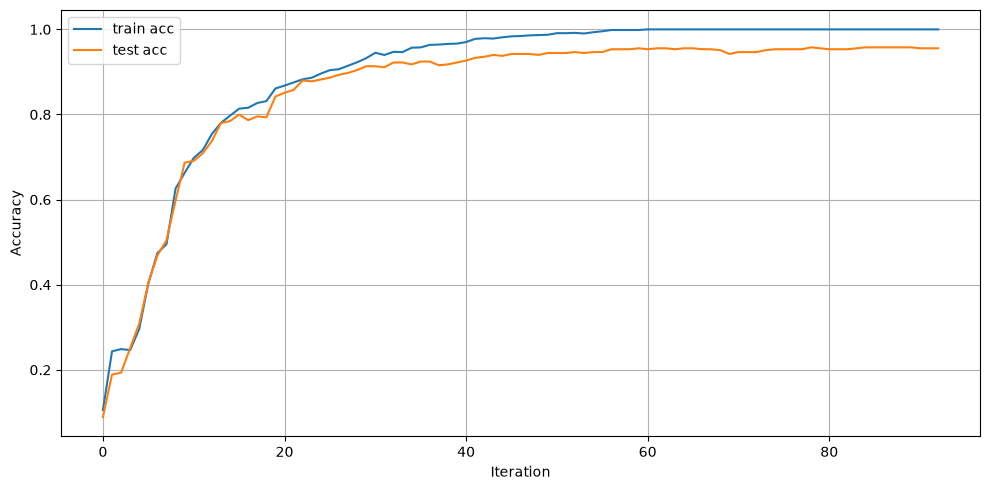

In [37]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(cb.train_acc, label="train acc")
ax.plot(cb.test_acc, label="test acc")
ax.set_xlabel("Iteration")
ax.set_ylabel("Accuracy")
ax.grid(True)
ax.legend()

fig.tight_layout()
plt.show()

### `Эксперименты с числом слоев (0.6 балла)`

Ясно, что из-за случайного начального приближения с каждым запуском обучения мы будем получать различное качество. Попробуем обучить нашу нейросеть с разным числом слоев несколько раз.

Заполните матрицы `accs_train` и `accs_test`. В позиции `[i, j]` должна стоять величина доли правильных ответов сети с $i+1$ полносвязными слоями при $j$-м запуске (все запуски идентичны).

In [38]:
accs_train = np.zeros((5, 5))
accs_test = np.zeros((5, 5))

In [39]:
for i in range(5):
    for j in range(5):
        network = make_network(input_size, hidden_layers_size, output_size, i + 1, ReLU)
        weights = get_weights(network)

        res = minimize(
            compute_loss_grad, weights,  
            args=[network, X_train, y_train], 
            method="L-BFGS-B",
            jac=True,
        )

        set_weights(res["x"], network)
        accs_train[i][j] = (predict(network, X_train) == y_train).mean()
        accs_test[i][j] = (predict(network, X_test) == y_test).mean()

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

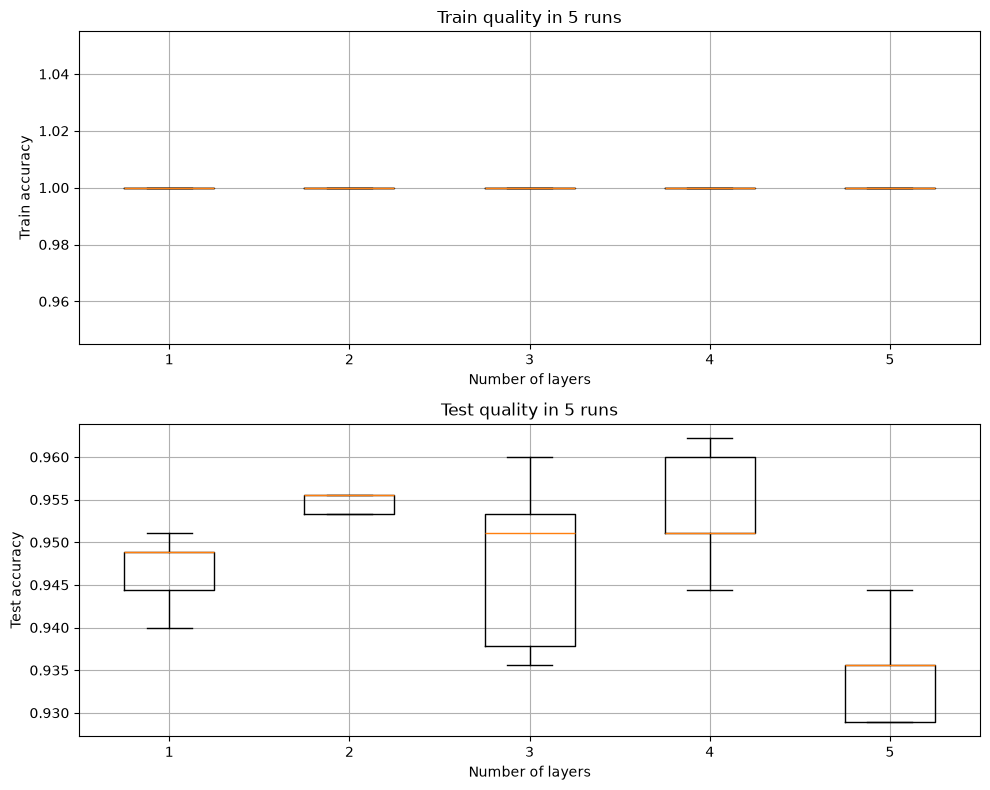

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].boxplot(accs_train.T, showfliers=False)
axes[1].boxplot(accs_test.T, showfliers=False)

axes[0].set_xlabel("Number of layers")
axes[1].set_xlabel("Number of layers")

axes[0].set_ylabel("Train accuracy")
axes[1].set_ylabel("Test accuracy")

axes[0].set_title("Train quality in 5 runs")
axes[1].set_title("Test quality in 5 runs")

axes[0].grid(True)
axes[1].grid(True)

fig.tight_layout()
plt.show()

Дайте развёрнутый ответ на вопросы (в этой же ячейке):
* Как изменяются качество на обучении и контроле и устойчивость процесса обучения при увеличении числа слоев?
* Можно ли сказать, что логистическая регрессия (линейная модель) дает качество хуже, чем нелинейная модель?

__Ответы:__

* Видно, что сначала модель запоминает какие-то зависимости, но после начинает переобучаться, и accuracy на тестовой выборке падает.
* На данном датасете разница очень маленькая, поэтому только на его основе ничего такого сказать нельзя. Однако, на датасетах с более большими картинками и большим число классов, нелинейная модель даст более хороший результат, чем просто логистическая регрессия.

### `Эксперименты c различными инициализациями весов (0.6 балла)`

Как уже было сказано, начальная инициализация весов нейронной сети может сильно влиять на процесс ее обучения и, как следствие, на ее качество.

В этом пункте вам предлагается попробовать обучить несколько нейронных сетей с различными инициализациями слоев.

Для этого необходимо реализовать функцию, инициализирующую веса линейных слоёв нашей нейронной сети. Добавьте в функционал данного метода возможность инициализировать его веса с помощью инициализации Kaiming (используется, если в нейронной сети в качестве функций активации используется ReLU) и инициализации Xavier (используется, если в нейронной сети в качестве функций активации используется Tanh или Sigmoid):

In [41]:
def initialize_network(network, initialization):
    for layer in network:
        if isinstance(layer, Dense):
            input_units, output_units = layer.weights.shape
            if initialization == 'Kaiming':
                R = (6 / (output_units)) ** 0.5
                layer.weights = np.random.uniform(low=-R, high=R, size=(input_units, output_units))
            elif initialization == 'Xavier':
                R = (6 / (input_units + output_units)) ** 0.5
                layer.weights = np.random.uniform(low=-R, high=R, size=(input_units, output_units))
            else:
                # Initialize weights with small random numbers from normal distribution.
                # In this case `initialization` represents a standard deviation
                # for normal distribution.
                layer.weights = np.random.randn(input_units, output_units) * initialization
            layer.biases = np.zeros_like(layer.biases)
            
            layer.params = [layer.weights, layer.biases]

Теперь попробуйте для каждой из 3 инициализаций обучить нейронную сеть несколько раз. Попробуйте проделать данную операцию при зафиксированном числе слоев равным 3, 4 и 5.

#### `3 слоя`

Зафиксируйте в сети число слоев равное трем.

Заполните матрицы `accs_train` и `accs_test`. В позиции `[i, j]` должна стоять величина доли правильных ответов сети при $j$-м запуске (все запуски идентичны) с инициализацией Kaiming при $i = 3$, с инициализацией Xavier при $i = 4$ и с инициализацией из нормального распределения с фиксированными параметрами при $0 \leqslant i \leqslant 2$ (попробуйте здесь 3 разных параметра для стандартного отклонения для нормального распределения, например: `1e-3`, `1e-2`, `1e-1`). Заметьте, что при большом числе слоев слишком низкое стандартное отклонение может не давать нейронной сети нормально обучиться.

In [42]:
init_vars = [1e-3, 1e-2, 1e-1, 'Kaiming', 'Xavier']

In [43]:
accs_train = np.zeros((5, 5))
accs_test = np.zeros((5, 5))

In [44]:
np.random.seed(42)
for i in range(5):
    for j in range(5):
        network = make_network(input_size, hidden_layers_size, output_size, 3, ReLU)
        initialize_network(network, init_vars[i])
        weights = get_weights(network)

        res = minimize(
            compute_loss_grad, weights,  
            args=[network, X_train, y_train], 
            method="L-BFGS-B",
            jac=True,
        )

        set_weights(res["x"], network)
        accs_train[i][j] = (predict(network, X_train) == y_train).mean()
        accs_test[i][j] = (predict(network, X_test) == y_test).mean()

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

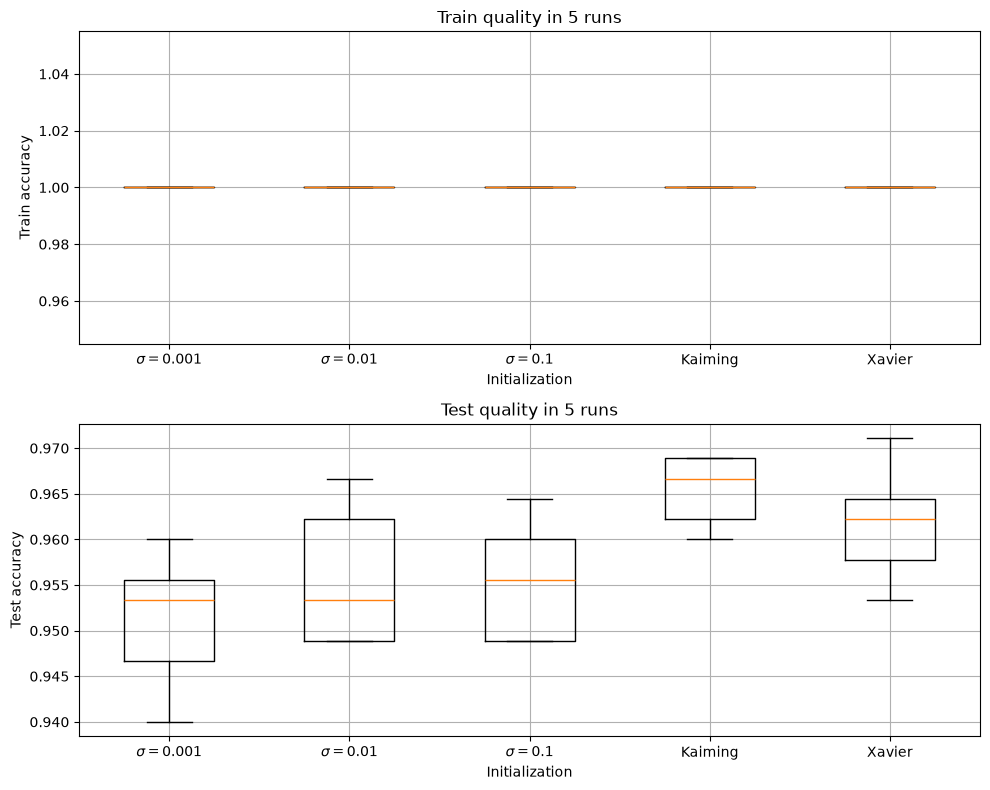

In [45]:
init_vars_for_plot = [(x if isinstance(x, str) else fr"$\sigma = {x}$") for x in init_vars]

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].boxplot(accs_train.T, tick_labels=init_vars_for_plot, showfliers=False)
axes[1].boxplot(accs_test.T, tick_labels=init_vars_for_plot, showfliers=False)

axes[0].set_xlabel("Initialization")
axes[1].set_xlabel("Initialization")

axes[0].set_ylabel("Train accuracy")
axes[1].set_ylabel("Test accuracy")

axes[0].set_title("Train quality in 5 runs")
axes[1].set_title("Test quality in 5 runs")

axes[0].grid(True)
axes[1].grid(True)

fig.tight_layout()
plt.show()

#### `4 слоя`

Выполните тут тот же код, что и в предыдущем пункте, но только уже с 4 слоями в сети.

In [46]:
init_vars = [5e-3, 1e-2, 1e-1, 'Kaiming', 'Xavier']

In [47]:
accs_train = np.zeros((5, 5))
accs_test = np.zeros((5, 5))

In [48]:
np.random.seed(42)
for i in range(5):
    for j in range(5):
        network = make_network(input_size, hidden_layers_size, output_size, 4, ReLU)
        initialize_network(network, init_vars[i])
        weights = get_weights(network)

        res = minimize(
            compute_loss_grad, weights,  
            args=[network, X_train, y_train], 
            method="L-BFGS-B",
            jac=True,
        )

        set_weights(res["x"], network)
        accs_train[i][j] = (predict(network, X_train) == y_train).mean()
        accs_test[i][j] = (predict(network, X_test) == y_test).mean()

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

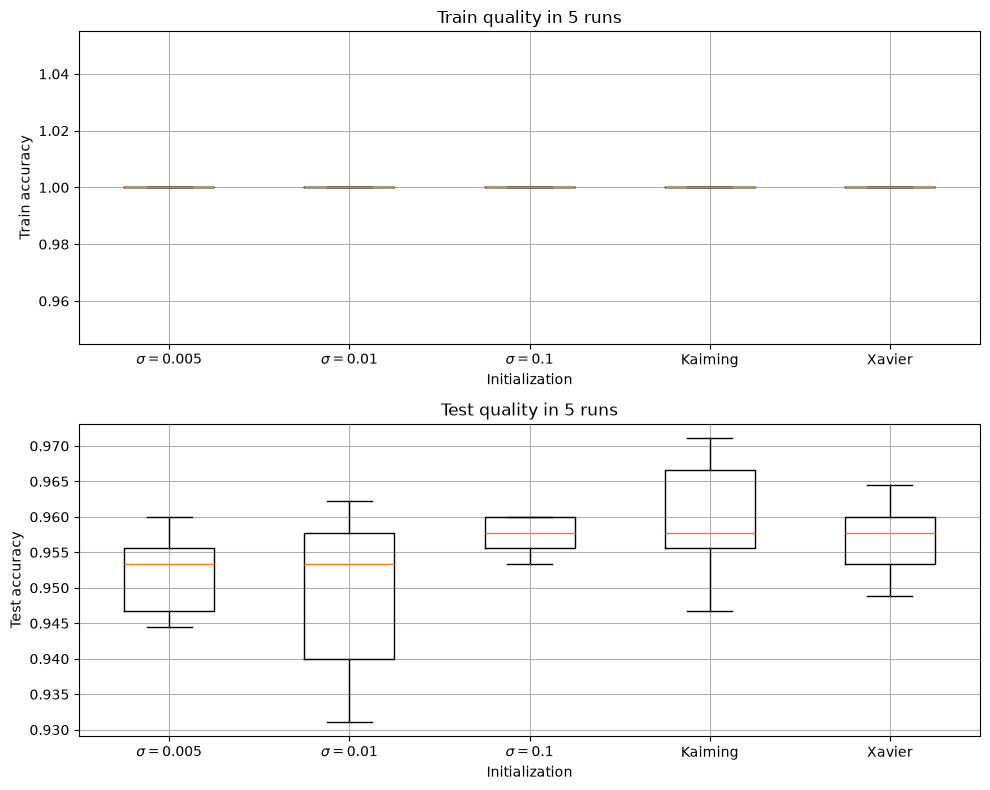

In [49]:
init_vars_for_plot = [(x if isinstance(x, str) else fr"$\sigma = {x}$") for x in init_vars]

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].boxplot(accs_train.T, tick_labels=init_vars_for_plot, showfliers=False)
axes[1].boxplot(accs_test.T, tick_labels=init_vars_for_plot, showfliers=False)

axes[0].set_xlabel("Initialization")
axes[1].set_xlabel("Initialization")

axes[0].set_ylabel("Train accuracy")
axes[1].set_ylabel("Test accuracy")

axes[0].set_title("Train quality in 5 runs")
axes[1].set_title("Test quality in 5 runs")

axes[0].grid(True)
axes[1].grid(True)

fig.tight_layout()
plt.show()

#### `5 слоев`

Выполните тут тот же код, что и в предыдущем пункте, но только уже с 5 слоями в сети.

In [50]:
init_vars = [1e-2, 1e-1, 1e0, 'Kaiming', 'Xavier']

In [51]:
accs_train = np.zeros((5, 5))
accs_test = np.zeros((5, 5))

In [52]:
np.random.seed(42)
for i in range(5):
    for j in range(5):
        network = make_network(input_size, hidden_layers_size, output_size, 5, ReLU)
        initialize_network(network, init_vars[i])
        weights = get_weights(network)

        res = minimize(
            compute_loss_grad, weights,  
            args=[network, X_train, y_train], 
            method="L-BFGS-B",
            jac=True,
        )

        set_weights(res["x"], network)
        accs_train[i][j] = (predict(network, X_train) == y_train).mean()
        accs_test[i][j] = (predict(network, X_test) == y_test).mean()

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

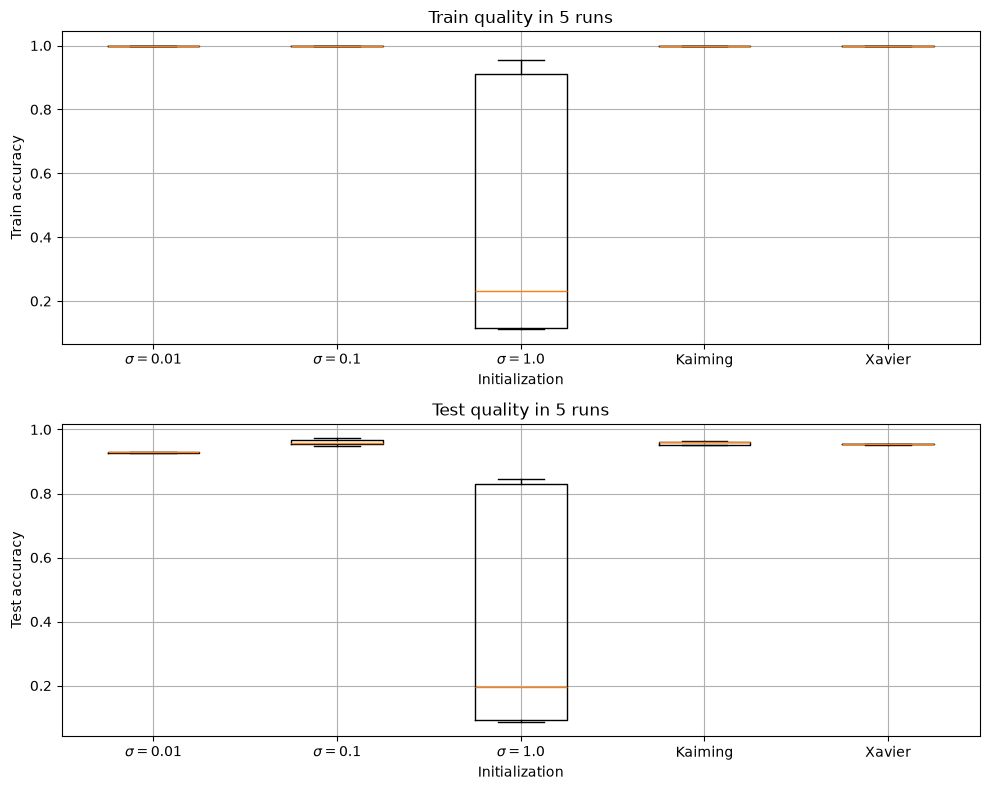

In [53]:
init_vars_for_plot = [(x if isinstance(x, str) else fr"$\sigma = {x}$") for x in init_vars]

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].boxplot(accs_train.T, tick_labels=init_vars_for_plot, showfliers=False)
axes[1].boxplot(accs_test.T, tick_labels=init_vars_for_plot, showfliers=False)

axes[0].set_xlabel("Initialization")
axes[1].set_xlabel("Initialization")

axes[0].set_ylabel("Train accuracy")
axes[1].set_ylabel("Test accuracy")

axes[0].set_title("Train quality in 5 runs")
axes[1].set_title("Test quality in 5 runs")

axes[0].grid(True)
axes[1].grid(True)

fig.tight_layout()
plt.show()

Дайте развёрнутый ответ на вопросы (в этой же ячейке):
* Как отличаются качество на обучении и контроле и устойчивость процесса обучения при различных инициализациях?
* Какие инициализации помогают обучать более глубокие сети?

__Ответы:__

* На таком маленьком датасете практически все модели полностью научились правильно отвечать на train. Однако, при стандартном отклонении $ 1 $, судя по всему, на глубокой модели произошел взрыв градиентов, и она не смогла обучиться. В остальном, на датасете такого размера все модели обучились на примерно один и тот же accuracy.
* Судя по графикам, практически лучше брать специализированную инициализацию - Xavier или Kaiming. Благодаря ним шанс затухания / взрыва градиентов становится меньше. Однако здесь для ReLU Kaiming не раскрылся на полную(

Теперь сравним скорость обучения при различных инициализациях. Создайте два списка списков `accs_test_on_iterations`, `accs_train_on_iterations` в каждом из которых в позиции `[i]` (см. описание `i` в предыдущем пункте) будет лежать список из значений `accuracy` на тестовой и обучающей выборках соотвественно, полученных во время обучения модели. Количество слоев в сети зафиксируйте равным 4.

In [54]:
init_vars = [1e-3, 1e-2, 1e-1, 'Kaiming', 'Xavier']

In [55]:
accs_test_on_iterations = []
accs_train_on_iterations = []

In [56]:
for i in range(5):
    network = make_network(input_size, hidden_layers_size, output_size, 4, ReLU)
    initialize_network(network, init_vars[i])
    weights = get_weights(network)

    cb = Callback(network, X_train, y_train, X_test, y_test, print=False)

    res = minimize(
        compute_loss_grad, weights,  
        args=[network, X_train, y_train], 
        method="L-BFGS-B",
        jac=True,
        callback=cb.call
    )

    set_weights(res["x"], network)
    accs_train_on_iterations.append(cb.train_acc)
    accs_test_on_iterations.append(cb.test_acc)

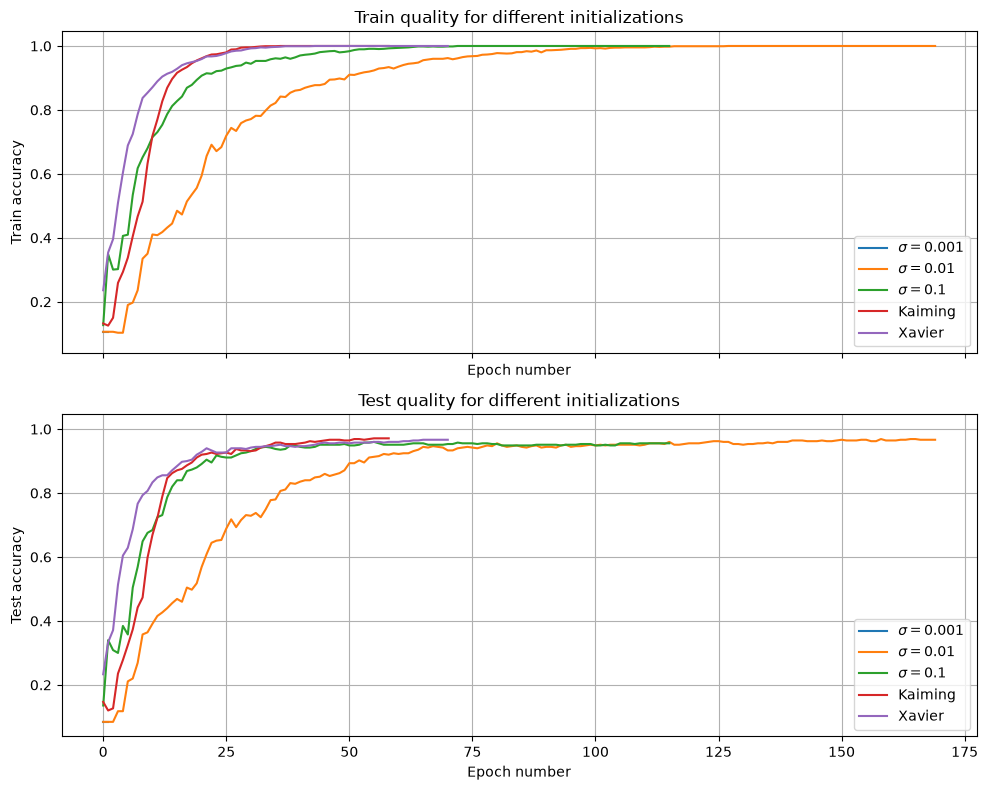

In [57]:
init_vars_for_plot = [(x if isinstance(x, str) else fr"$\sigma = {x}$") for x in init_vars]

fig, ax = plt.subplots(2, 1, sharex=True, sharey=True,  figsize=(10, 8))

for idx, label in enumerate(init_vars_for_plot):
    ax[0].plot(accs_train_on_iterations[idx], label=label)
    ax[1].plot(accs_test_on_iterations[idx], label=label)

for idx, key in enumerate(["Train", "Test"]):
    ax[idx].set_title(f"{key} quality for different initializations")
    ax[idx].set_xlabel("Epoch number")
    ax[idx].set_ylabel(f"{key} accuracy")
    ax[idx].grid(True)
    ax[idx].legend()



fig.tight_layout()
plt.show()

Дайте развёрнутый ответ на вопросы (в этой же ячейке):
* Как меняется скорость cходимости в зависимости от выбранной инициализации?

__Ответы:__

На очень маленьком $ \sigma $ модель вообще не смогла обучиться, видимо из-за затухших градиентов.
А так видна закономерность:
- С маленькими $ \sigma $ модель сходится дольше
- На специальных инициализациях модель сходится быстрее, при этом с нормальным качеством

### `Эксперименты c различными функциями активации (0.6 балла)`

Проверим теперь, с какой функцией активации нейронная сеть будет обучаться лучше.

В этом пункте вам предлагается попробовать обучить несколько нейронных сетей с различными функциями активации.

Для этого нам нужно реализовать еще 2 слоя: для функций активации `Tanh` и `Sigmoid`.

In [58]:
class Tanh:
    """
    tanh(y) = (e^y - e^(-y)) / (e^y + e^(-y))
    Используйте функцию np.tanh для подсчета гиперболического тангенса.
    Вы можете сами реализовать подсчет tanh, но тогда вам нужно устойчиво его вычислять.
    """
    def __init__(self):
        self.params = [] # Tanh has no parameters

    def forward(self, input):
        """
        Apply elementwise Tanh to [batch, num_units] matrix
        """

        self.output = np.tanh(input)
        return self.output

    def backward(self, grad_output):
        """
        Compute gradient of loss w.r.t. Tanh input
        grad_output shape: [batch, num_units]
        output 1 shape: [batch, num_units]
        output 2: []
        """

        deriv = 1 - self.output ** 2
        return grad_output * deriv, []

    def __repr__(self):
        return 'Tanh()'

In [59]:
from scipy.special import expit
    
class Sigmoid:
    """
    sigmoid(y) = 1 / (1 + e^(-y))
    Используйте функцию expit для подсчета сигмоиды.
    Вы можете сами реализовать подсчет сигмоиды, но тогда вам нужно устойчиво ее вычислять.
    """
    def __init__(self):
        self.params = [] # Sigmoid has no parameters

    def forward(self, input):
        """
        Apply elementwise Sigmoid to [batch, num_units] matrix
        """
        
        self.output = expit(input)
        return self.output

    def backward(self, grad_output):
        """
        Compute gradient of loss w.r.t. Sigmoid input
        grad_output shape: [batch, num_units]
        output 1 shape: [batch, num_units]
        output 2: []
        """

        deriv = self.output * (1 - self.output)
        return grad_output * deriv, []

    def __repr__(self):
        return 'Sigmoid()'

Теперь попробуйте для каждой из 3 функций активации обучить нейронную сеть несколько раз. Число слоев зафиксируйте равным 3. В случае `Tanh` и `Sigmoid` используйте инициализацию `Xavier`, а в случае `ReLU` используйте инициализацию `Kaiming`.

Заполните матрицы `accs_train` и `accs_test`. В позиции `[i, j]` должна стоять величина доли правильных ответов сети при $j$-м запуске (все запуски идентичны) с функцией активации $ReLU$ при $i = 0$, с функцией активации $Tanh$ при $i = 1$ и с функцией активации $Sigmoid$ при $i = 2$.

In [60]:
act_func_vars = ['ReLU', 'Tanh', 'Sigmoid']
init_for_act_funcs = ['Kaiming', 'Xavier', 'Xavier']

activation_classes = {
    'Tanh': Tanh,
    'Sigmoid': Sigmoid,
    'ReLU': ReLU,
}

In [61]:
accs_train = np.zeros((3, 5))
accs_test = np.zeros((3, 5))

In [62]:
for i in range(3):
    for j in range(5):
        act_f = act_func_vars[i]
        network = make_network(input_size, hidden_layers_size, output_size, 3, activation_classes[act_f])
        initialize_network(network, init_for_act_funcs[i])
        weights = get_weights(network)

        res = minimize(
            compute_loss_grad, weights,  
            args=[network, X_train, y_train], 
            method="L-BFGS-B",
            jac=True,
        )

        set_weights(res["x"], network)
        accs_train[i][j] = (predict(network, X_train) == y_train).mean()
        accs_test[i][j] = (predict(network, X_test) == y_test).mean()

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

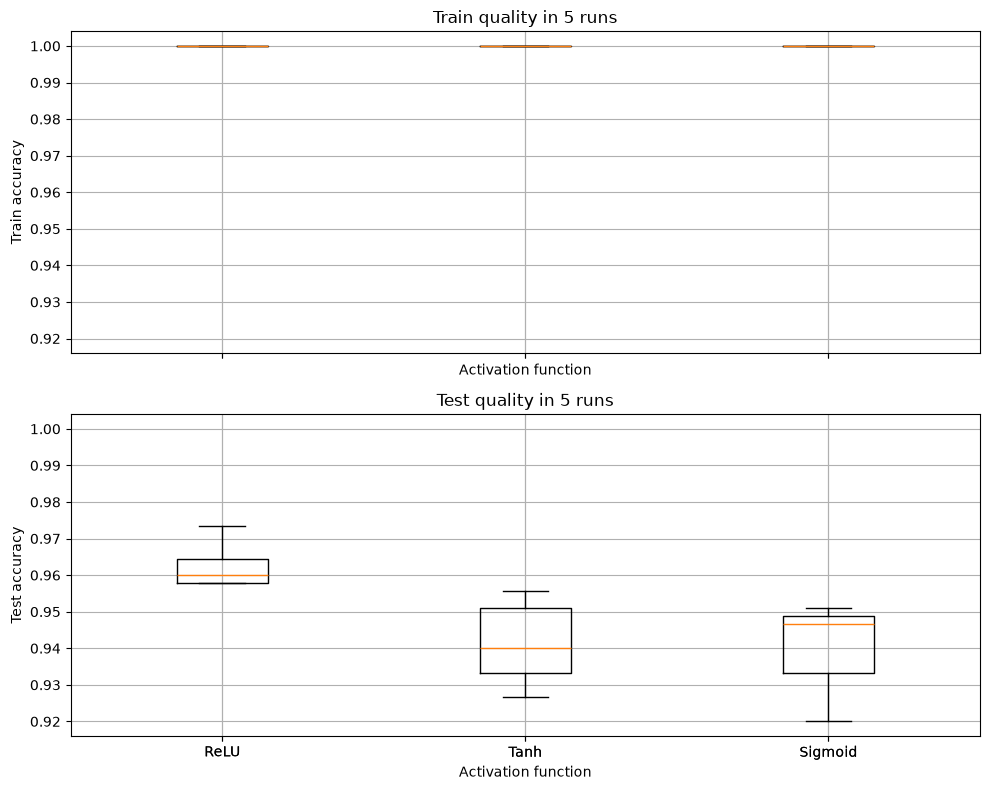

In [63]:
fig, ax = plt.subplots(2, 1, sharex=True, sharey=True,  figsize=(10, 8))

ax[0].boxplot(accs_train.T, tick_labels=act_func_vars, showfliers=False)
ax[1].boxplot(accs_test.T, tick_labels=act_func_vars, showfliers=False)

ax[0].set_title("Train quality in 5 runs")
ax[1].set_title("Test quality in 5 runs")

ax[0].set_xlabel("Activation function")
ax[1].set_xlabel("Activation function")

ax[0].set_ylabel("Train accuracy")
ax[1].set_ylabel("Test accuracy")

ax[0].grid(True)
ax[1].grid(True)

fig.tight_layout()
plt.show()

Дайте развёрнутый ответ на вопросы (в этой же ячейке):
* Как отличаются качество на обучении и контроле и устойчивость процесса обучения при различных функциях активации?

__Ответы:__

Видим, что ReLU немного побеждает своих конкурентов.
Вероятно это связано с тем, что она неограничено растет (а не стремится к асимптотам) $ \Rightarrow $ шанс затухания градиента ниже.
Несмотря на это, все функции активации показали довольно хороший результат.

\* Несколько фрагментов кода в задании написаны на основе материалов [курса по глубинному обучению на ФКН НИУ ВШЭ](https://www.hse.ru/ba/ami/courses/205504078.html)

### `Реализация метода оптимизации (1.4 балла)`

В этой части задания реализуйте метод оптимизации SGD + momentum. Упрощённая версия более общего алгоритма [отсюда](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html):

$$
\begin{aligned}
    &\rule{70mm}{0.4pt}                                                             \\
    &\textbf{input}      : \gamma \text{ (lr)}, \: \theta_0 \text{ (params)}, \: X \text{ (data)},       \\
    &\hspace{13mm} \: f(\theta) \text{ (objective)}, \:\mu \text{ (momentum)}       \\[-1.ex]
    &\rule{70mm}{0.4pt}                                                             \\
    &\textbf{for} \: t=1 \: \textbf{to} \: \ldots \: \textbf{do}                    \\
    &\hspace{5mm}\mathcal{X} \leftarrow \texttt{list\_of\_random\_batches}(X)\\
    &\hspace{5mm}\textbf{for} \: i=1 \: \textbf{to} \: \ldots \: \textbf{do}                    \\
    &\hspace{10mm}g_t\leftarrow   \nabla_{\theta} f_t (\theta_{t-1},\mathcal{X}_i)      \\
    &\hspace{10mm}\textbf{if} \: \mu \neq 0                                          \\
    &\hspace{15mm}\textbf{if} \: t > 1                                              \\
    &\hspace{20mm} \textbf{b}_t \leftarrow \mu \textbf{b}_{t-1} + g_t               \\
    &\hspace{15mm}\textbf{else}                                                     \\
    &\hspace{20mm} \textbf{b}_t \leftarrow g_t                                      \\
    &\hspace{15mm} g_t  \leftarrow  \textbf{b}_t                                     \\
    &\hspace{10mm}\theta_t \leftarrow \theta_{t-1} - \gamma g_t                      \\[-1.ex]
    &\rule{70mm}{0.4pt}                                                             \\[-1.ex]
    &\bf{return} \:  \theta_t                                                       \\[-1.ex]
    &\rule{70mm}{0.4pt}                                                             \\[-1.ex]
\end{aligned}
$$

Проще всего будет написать `custom minimizer` (смотри [документацию scipy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)).

In [64]:
from scipy.optimize import OptimizeResult


def SGD(fun, x0, args, **kwargs) -> OptimizeResult:
    global inference

    inference = False

    callback = kwargs['callback']   # feed weights from each iteration to update network and log metrics
    mu = kwargs['momentum']
    n_iter = kwargs['n_iter']
    gamma = kwargs['lr']
    jac = kwargs['jac']
    batch_size = kwargs['batch_size']

    eps = 1e-8
    
    net, X, y = args
    x0 = x0.copy()

    total_grad = None
    for t in range(1, n_iter + 1):
        indices = np.random.permutation(len(X))

        for start in range(0, len(X), batch_size):
            batch_indices = indices[start:start + batch_size]
            X_batch = X[batch_indices]
            y_batch = y[batch_indices]

            if jac is True:
                loss, grad = fun(x0, [net, X_batch, y_batch])
            else:
                loss = fun(x0, [net, X_batch, y_batch])
                grad = jac(x0, [net, X_batch, y_batch])

            if t == 1 and start == 0:
                total_grad = grad
            else:
                total_grad = mu * total_grad + grad

            x0 -= gamma * total_grad

        inference = True
        if jac is True:
            loss, grad = fun(x0, [net, X, y])
        else:
            loss = fun(x0, [net, X, y])
            grad = jac(x0, [net, X, y])
        inference = False

        callback(x0)

        if np.sum(grad ** 2) < eps:
            n_iter = t
            break

    inference = True

    result = fun(x0, [net, X, y])
    final_loss = result[0] if jac is True else result

    return OptimizeResult(
        x=x0,
        fun=final_loss,
        nit=n_iter,
        success=True,
    )

**Задание 1. (0.5 балла)** Продемонстрируйте правильную работу метода оптимизации, получив `test_accuracy>=0.9`.

In [65]:
network = make_network(input_size, hidden_layers_size, output_size, 3, ReLU)
initialize_network(network, "Kaiming")
weights = get_weights(network)
cb = Callback(network, X_train, y_train, X_test, y_test, print=True)

res = SGD(
    compute_loss_grad, weights,  
    args=[network, X_train, y_train],
    momentum=0.9,
    n_iter = 64,
    lr = 1e-3,
    batch_size = 32,
    jac=True,
    callback=cb.call
)

Train:
 ACC = 0.6206384558277654
Test:
 ACC = 0.5688888888888889

Train:
 ACC = 0.7542687453600594
Test:
 ACC = 0.7155555555555555

Train:
 ACC = 0.8366740905716407
Test:
 ACC = 0.8044444444444444

Train:
 ACC = 0.8611729769858946
Test:
 ACC = 0.8222222222222222

Train:
 ACC = 0.8938381588715665
Test:
 ACC = 0.84

Train:
 ACC = 0.9005196733481812
Test:
 ACC = 0.8666666666666667

Train:
 ACC = 0.933184855233853
Test:
 ACC = 0.8844444444444445

Train:
 ACC = 0.9368968077208611
Test:
 ACC = 0.9

Train:
 ACC = 0.949517446176689
Test:
 ACC = 0.8866666666666667

Train:
 ACC = 0.9480326651818857
Test:
 ACC = 0.9

Train:
 ACC = 0.9561989606533037
Test:
 ACC = 0.9111111111111111

Train:
 ACC = 0.9643652561247216
Test:
 ACC = 0.9088888888888889

Train:
 ACC = 0.9710467706013363
Test:
 ACC = 0.92

Train:
 ACC = 0.9725315515961396
Test:
 ACC = 0.9244444444444444

Train:
 ACC = 0.9673348181143281
Test:
 ACC = 0.9222222222222223

Train:
 ACC = 0.9740163325909429
Test:
 ACC = 0.9177777777777778

Trai

**Задание 2. (0.8 балла)** Сравните три алгоритма:
1. LBFGS-B
2. SGD
3. SGD + momentum

Для этого одновременно переберите следующие гиперпараметры:
- значения `lr` на отрезке `[1e-3, 1e-1]` по логарифмической сетке
- два значения `momentum`: `0` и `0.9`
- значения `batch_size`: `8` и `32`

В каждом запуске сохраняйте три метрики: итоговое accuracy на тесте и на трейне и время обучения.

Для каждого из трёх алгоритмов выберите лучшие `lr` и `batch_size` по `test_accuracy`. Постройте для них кривые обучения (пример ниже). Сделайте выводы.

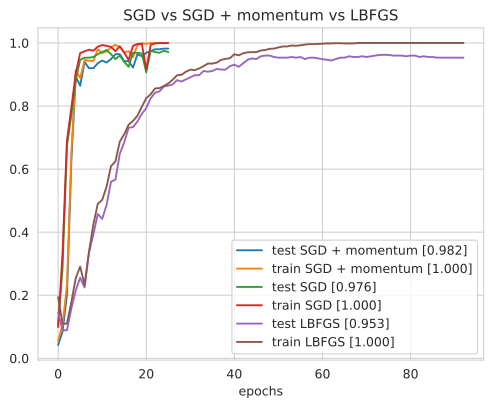

In [66]:
from time import perf_counter

lr_vars = np.logspace(-3, -1, num=5)
batch_size_vars = [8, 32]

np.random.seed(42)

network = make_network(input_size, hidden_layers_size, output_size, 4, ReLU)
initialize_network(network, "Kaiming")
initial_weights = get_weights(network).copy()

#--------
weights = initial_weights.copy()
cb_lbfgsb = Callback(network, X_train, y_train, X_test, y_test, print=False)

start_time = perf_counter()
res_lbfgsb = minimize(
    compute_loss_grad, weights,  
    args=[network, X_train, y_train], 
    method="L-BFGS-B",
    jac=True,
    callback=cb_lbfgsb.call
)
elapsed_lbfsgb = perf_counter() - start_time

lbfgsb_metrics = (
    (predict(network, X_train) == y_train).mean(),
    (predict(network, X_test) == y_test).mean(),
    elapsed_lbfsgb,
)
#--------


#--------
sgd_res = dict()
batch_size_best_sgd = []

for batch_size in batch_size_vars:
    acc = 0
    best_params = None
    
    for lr in lr_vars:
        weights = initial_weights.copy()

        cb = Callback(network, X_train, y_train, X_test, y_test, print=False)

        start_time = perf_counter()
        res = SGD(
            compute_loss_grad, weights,  
            args=[network, X_train, y_train],
            momentum=0,
            n_iter = 100,
            lr = lr,
            batch_size = batch_size,
            jac=True,
            callback=cb.call
        )
        elapsed = perf_counter() - start_time

        set_weights(res["x"], network)
        train_acc = (predict(network, X_train) == y_train).mean()
        test_acc = (predict(network, X_test) == y_test).mean()

        sgd_res[(batch_size, lr)] = (train_acc, test_acc, elapsed)

        if acc < test_acc:
            acc = test_acc
            best_params = (cb, lr, res["x"].copy())

    batch_size_best_sgd.append(best_params)
#--------

#--------
momentum_res = dict()
batch_size_best_momentum = []

for batch_size in batch_size_vars:
    acc = 0
    best_params = None
    
    for lr in lr_vars:
        weights = initial_weights.copy()

        cb = Callback(network, X_train, y_train, X_test, y_test, print=False)

        start_time = perf_counter()
        res = SGD(
            compute_loss_grad, weights,  
            args=[network, X_train, y_train],
            momentum=0.9,
            n_iter = 100,
            lr = lr,
            batch_size = batch_size,
            jac=True,
            callback=cb.call
        )
        elapsed = perf_counter() - start_time

        set_weights(res["x"], network)
        train_acc = (predict(network, X_train) == y_train).mean()
        test_acc = (predict(network, X_test) == y_test).mean()

        momentum_res[(batch_size, lr)] = (train_acc, test_acc, elapsed)

        if acc < test_acc:
            acc = test_acc
            best_params = (cb, lr, res["x"].copy())

    batch_size_best_momentum.append(best_params)
#--------

In [67]:
best_sgd_key = max(
    sgd_res,
    key=lambda key: sgd_res[key][1]
)
best_momentum_key = max(
    momentum_res,
    key=lambda key: momentum_res[key][1],
)
print("SGD: batch_size, lr =", best_sgd_key)
print("SGD + momentum: batch_size, lr =", best_momentum_key)
print()
print("L-BFGS-B time =", elapsed_lbfsgb)
print("SGD time =", sgd_res[best_sgd_key][2])
print("SGD + momentum =", momentum_res[best_momentum_key][2])

SGD: batch_size, lr = (32, np.float64(0.03162277660168379))
SGD + momentum: batch_size, lr = (8, np.float64(0.0031622776601683794))

L-BFGS-B time = 0.10013075001188554
SGD time = 0.6420427909906721
SGD + momentum = 1.9440229589963565


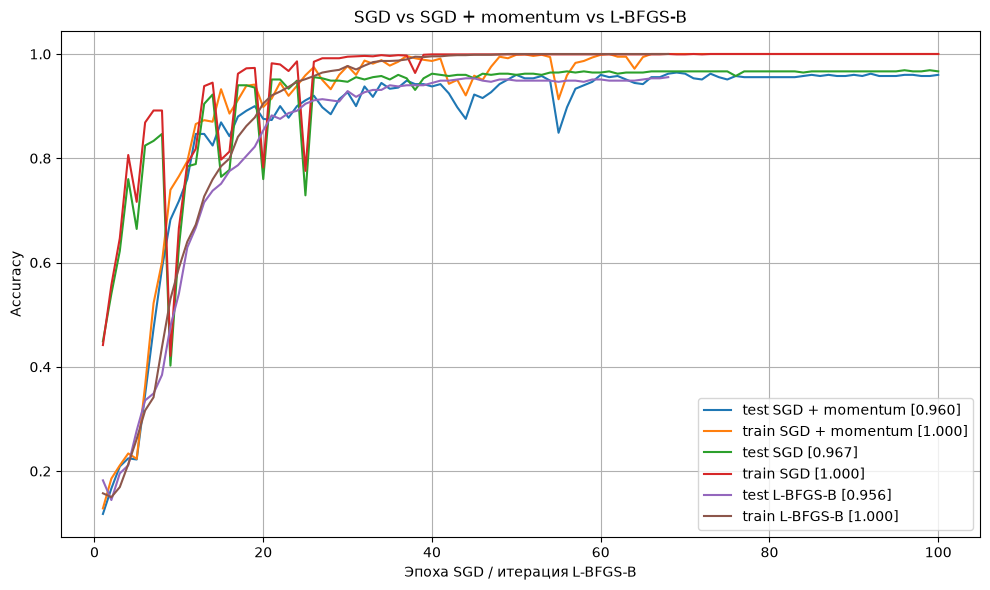

In [68]:
cb_sgd = batch_size_best_sgd[
    batch_size_vars.index(best_sgd_key[0])
][0]

cb_momentum = batch_size_best_momentum[
    batch_size_vars.index(best_momentum_key[0])
][0]

# plot by chatgpt
fig, ax = plt.subplots(figsize=(10, 6))

for name, cb in [
    ("SGD + momentum", cb_momentum),
    ("SGD", cb_sgd),
    ("L-BFGS-B", cb_lbfgsb),
]:
    steps = np.arange(1, len(cb.train_acc) + 1)

    ax.plot(
        steps, cb.test_acc,
        label=f"test {name} [{cb.test_acc[-1]:.3f}]",
    )
    ax.plot(
        steps, cb.train_acc,
        label=f"train {name} [{cb.train_acc[-1]:.3f}]",
    )

ax.set_title("SGD vs SGD + momentum vs L-BFGS-B")
ax.set_xlabel("Эпоха SGD / итерация L-BFGS-B")
ax.set_ylabel("Accuracy")
ax.grid(True)
ax.legend()
fig.tight_layout()
plt.show()

**Выводы:** судя по всему, из-за того что в SGD имеется случайность, мы нашли более хороший оптимум (и получили более хороший accuracy на тестовой выборке). Видно, что просто SGD вначале "штормит".

**Задание 3. (0.1 балла)** Для отобранных в прошлом задании трёх алгоритмов ответье на вопрос: как меняются запуски для двух значений `batch_size`.

In [69]:
for batch_size in batch_size_vars:
    cnt = 0
    avg_sgd_time = 0
    for key, value in sgd_res.items():
        if key[0] == batch_size and value[1] > 0.5:
            cnt += 1
            avg_sgd_time += value[2]
    avg_sgd_time /= cnt

    print(f"Average SGD (batch = {batch_size}) time = {avg_sgd_time}")

print()

for batch_size in batch_size_vars:
    cnt = 0
    avg_sgdm_time = 0
    for key, value in momentum_res.items():
        if key[0] == batch_size and value[1] > 0.5:
            cnt += 1
            avg_sgdm_time += value[2]
    avg_sgdm_time /= cnt

    print(f"Average SGD + momentum (batch = {batch_size}) time = {avg_sgdm_time}")

Average SGD (batch = 8) time = 1.9950884897480137
Average SGD (batch = 32) time = 0.6490931144944625

Average SGD + momentum (batch = 8) time = 1.9524064584984444
Average SGD + momentum (batch = 32) time = 0.6321852914988995


SGD
  batch=8, lr=0.01: train=1.0000, test=0.9533, время=2.00 с
  batch=32, lr=0.0316: train=1.0000, test=0.9667, время=0.64 с


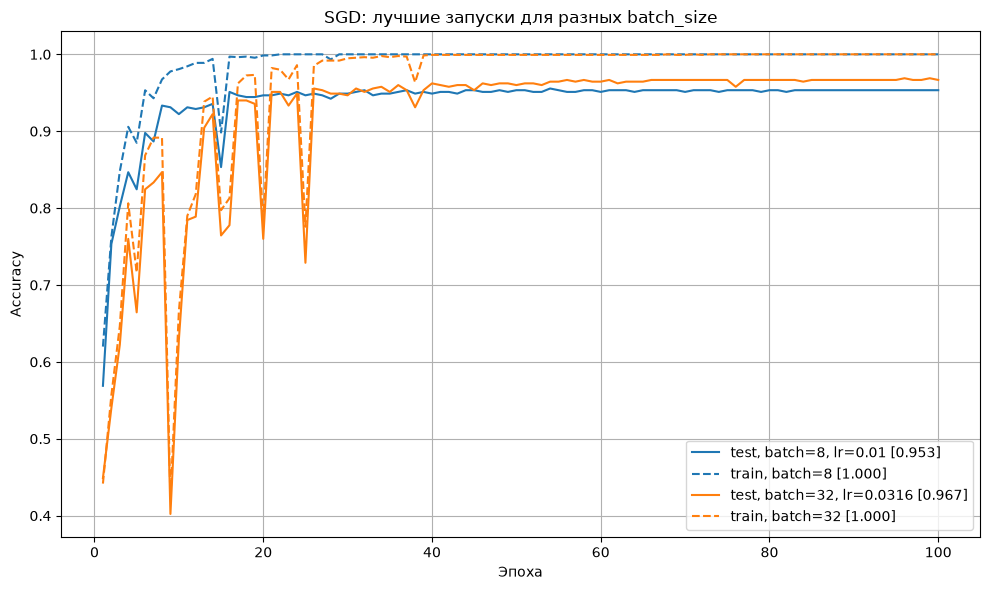


SGD + momentum
  batch=8, lr=0.00316: train=1.0000, test=0.9600, время=1.94 с
  batch=32, lr=0.00316: train=1.0000, test=0.9556, время=0.63 с


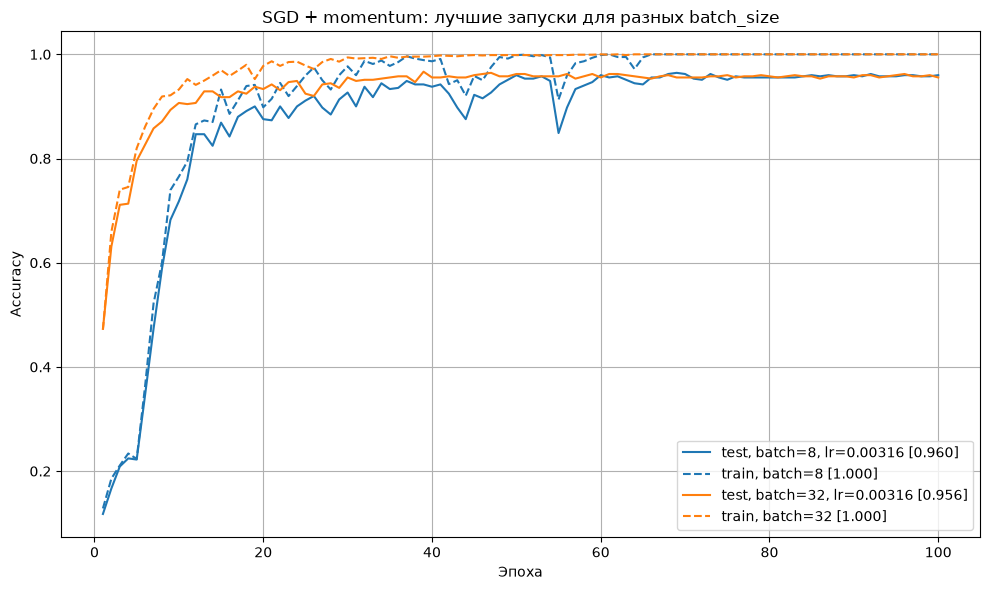

In [70]:
# plot by chatgpt
for name, best_runs, results in [
    ("SGD", batch_size_best_sgd, sgd_res),
    ("SGD + momentum", batch_size_best_momentum, momentum_res),
]:
    fig, ax = plt.subplots(figsize=(10, 6))
    print(name)

    for batch_size, (cb, lr, _) in zip(batch_size_vars, best_runs):
        train_acc, test_acc, elapsed = results[(batch_size, lr)]
        epochs = np.arange(1, len(cb.train_acc) + 1)

        line, = ax.plot(
            epochs, cb.test_acc,
            label=f"test, batch={batch_size}, lr={lr:.3g} [{test_acc:.3f}]",
        )
        ax.plot(
            epochs, cb.train_acc,
            color=line.get_color(),
            linestyle="--",
            label=f"train, batch={batch_size} [{train_acc:.3f}]",
        )

        print(
            f"  batch={batch_size}, lr={lr:.3g}: "
            f"train={train_acc:.4f}, test={test_acc:.4f}, "
            f"время={elapsed:.2f} с"
        )

    ax.set_title(f"{name}: лучшие запуски для разных batch_size")
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Accuracy")
    ax.grid(True)
    ax.legend()
    fig.tight_layout()
    plt.show()
    print()

**Ответ:**

С более большими батчами обучение происходит быстрее по времени, других трендов не обнаружено

## `Бонусная часть`

### `Реализация метода оптимизации (1 балл)`

Реализуйте метод оптимизации Adam и сравните его работу с SGD + momentum, проведя эксперимент, как в задании 2 (перебор гиперпараметров + кривые обучения).

In [71]:
from scipy.optimize import OptimizeResult


def Adam(fun, x0, args, **kwargs) -> OptimizeResult:
    global inference
    inference = False

    callback = kwargs['callback']   # feed weights from each iteration to update network and log metrics
    n_iter = kwargs['n_iter']
    gamma = kwargs['lr']
    beta_1 = kwargs['beta_1']
    beta_2 = kwargs['beta_2']
    batch_size = kwargs['batch_size']
    jac = kwargs['jac']

    eps = 1e-8
    
    net, X, y = args
    x0 = x0.copy()

    m = np.zeros_like(x0)
    v = np.zeros_like(x0)

    step = 0
    for t in range(1, n_iter + 1):
        indices = np.random.permutation(len(X))

        for start in range(0, len(X), batch_size):
            batch_indices = indices[start:start + batch_size]
            X_batch = X[batch_indices]
            y_batch = y[batch_indices]
            if jac is True:
                loss, grad = fun(x0, [net, X_batch, y_batch])
            else:
                loss = fun(x0, [net, X_batch, y_batch])
                grad = jac(x0, [net, X_batch, y_batch])

            step += 1
            m = beta_1 * m + (1 - beta_1) * grad
            v = beta_2 * v + (1 - beta_2) * (grad ** 2)

            m_hat = m / (1 - beta_1 ** step)
            v_hat = v / (1 - beta_2 ** step)

            x0 -= gamma * (m_hat / (np.sqrt(v_hat) + eps))

        inference = True
        if jac is True:
            loss, grad = fun(x0, [net, X, y])
        else:
            loss = fun(x0, [net, X, y])
            grad = jac(x0, [net, X, y])
        inference = False

        callback(x0)

        if np.sum(grad ** 2) < eps:
            n_iter = t
            break
        
    inference = True

    result = fun(x0, [net, X, y])
    final_loss = result[0] if jac is True else result

    return OptimizeResult(
        x=x0,
        fun=final_loss,
        nit=n_iter,
        success=True,
    )

In [72]:
network = make_network(input_size, hidden_layers_size, output_size, 3, ReLU)
initialize_network(network, "Kaiming")
weights = get_weights(network)
cb = Callback(network, X_train, y_train, X_test, y_test, print=True)

res = Adam(
    compute_loss_grad, weights,  
    args=[network, X_train, y_train],
    n_iter = 64,
    lr = 1e-3,
    beta_1 = 0.9,
    beta_2 = 0.999,
    batch_size=32,
    jac=True,
    callback=cb.call
)

Train:
 ACC = 0.28433556050482556
Test:
 ACC = 0.2911111111111111

Train:
 ACC = 0.47141796585003715
Test:
 ACC = 0.44

Train:
 ACC = 0.5597624350408315
Test:
 ACC = 0.4955555555555556

Train:
 ACC = 0.6599851521900519
Test:
 ACC = 0.5666666666666667

Train:
 ACC = 0.7141796585003712
Test:
 ACC = 0.6222222222222222

Train:
 ACC = 0.7668893838158871
Test:
 ACC = 0.6911111111111111

Train:
 ACC = 0.8144023756495917
Test:
 ACC = 0.7111111111111111

Train:
 ACC = 0.8433556050482554
Test:
 ACC = 0.7422222222222222

Train:
 ACC = 0.8693392724573126
Test:
 ACC = 0.7733333333333333

Train:
 ACC = 0.8901262063845583
Test:
 ACC = 0.7777777777777778

Train:
 ACC = 0.9049740163325909
Test:
 ACC = 0.8044444444444444

Train:
 ACC = 0.9205642167780252
Test:
 ACC = 0.7977777777777778

Train:
 ACC = 0.9361544172234595
Test:
 ACC = 0.8266666666666667

Train:
 ACC = 0.9376391982182628
Test:
 ACC = 0.8333333333333334

Train:
 ACC = 0.947290274684484
Test:
 ACC = 0.8377777777777777

Train:
 ACC = 0.9569413

In [73]:
lr_vars = np.logspace(-3, -1, num=5)
beta_1_vars = 1 - np.logspace(np.log10(0.5), np.log10(0.01), num=5)
beta_2_vars = 1 - np.logspace(-1, -4, num=4)
batch_size_vars = [8, 32]

adam_res = dict()
acc = 0
best_params = None

np.random.seed(42)

network = make_network(input_size, hidden_layers_size, output_size, 4, ReLU)
for batch_size in batch_size_vars:    
    for beta_1 in beta_1_vars:
        for beta_2 in beta_2_vars:
            for lr in lr_vars:
                weights = initial_weights.copy()

                cb = Callback(network, X_train, y_train, X_test, y_test, print=False)

                start_time = perf_counter()
                res = Adam(
                    compute_loss_grad, weights,  
                    args=[network, X_train, y_train],
                    n_iter = 100,
                    lr = lr,
                    beta_1 = beta_1,
                    beta_2 = beta_2,
                    batch_size=batch_size,
                    jac=True,
                    callback=cb.call
                )
                elapsed = perf_counter() - start_time

                set_weights(res["x"], network)
                train_acc = (predict(network, X_train) == y_train).mean()
                test_acc = (predict(network, X_test) == y_test).mean()

                adam_res[(batch_size, lr, beta_1, beta_2)] = (train_acc, test_acc, elapsed)

                if acc < test_acc:
                    acc = test_acc
                    best_params = (cb, batch_size, lr, beta_1, beta_2, res["x"].copy())

In [74]:
best_adam_key = max(
    adam_res,
    key=lambda key: adam_res[key][1]
)

print("Adam: batch_size, lr, beta_1, beta_2 =", best_adam_key)
print("Adam time =", adam_res[best_adam_key][2])

Adam: batch_size, lr, beta_1, beta_2 = (8, np.float64(0.0031622776601683794), np.float64(0.8119698453456803), np.float64(0.999))
Adam time = 1.4031561669980874


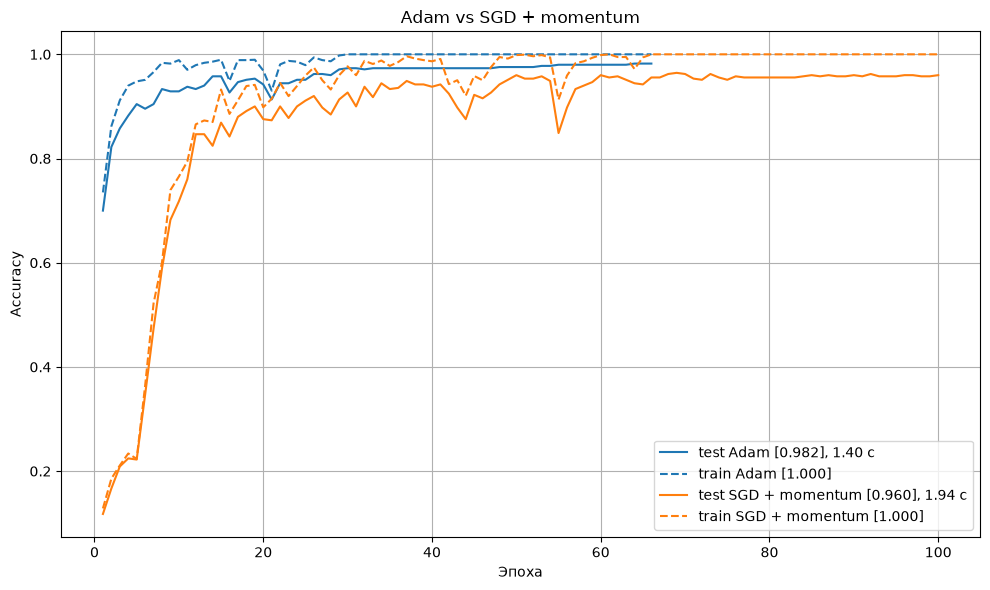

In [75]:
# plot by chatgpt
cb_adam = best_params[0]

fig, ax = plt.subplots(figsize=(10, 6))

for name, cb, elapsed in [
    ("Adam", cb_adam, adam_res[best_adam_key][2]),
    ("SGD + momentum", cb_momentum, momentum_res[best_momentum_key][2]),
]:
    epochs = np.arange(1, len(cb.train_acc) + 1)

    line, = ax.plot(
        epochs, cb.test_acc,
        label=f"test {name} [{cb.test_acc[-1]:.3f}], {elapsed:.2f} с",
    )
    ax.plot(
        epochs, cb.train_acc,
        color=line.get_color(),
        linestyle="--",
        label=f"train {name} [{cb.train_acc[-1]:.3f}]",
    )

ax.set_title("Adam vs SGD + momentum")
ax.set_xlabel("Эпоха")
ax.set_ylabel("Accuracy")
ax.grid(True)
ax.legend()
fig.tight_layout()
plt.show()

In [76]:
cnt = 0
avg_sgdm_time = 0
for key, value in momentum_res.items():
    if value[1] > 0.5:
        cnt += 1
        avg_sgdm_time += value[2]
avg_sgdm_time /= cnt

cnt = 0
avg_adam_time = 0
for key, value in adam_res.items():
    if value[1] > 0.5:
        cnt += 1
        avg_adam_time += value[2]
avg_adam_time /= cnt

print("Average SGD + momentum time =", avg_sgdm_time)
print("Average Adam time =", avg_adam_time)

Average SGD + momentum time = 1.292295874998672
Average Adam time = 1.2376145346375602


**Выводы:** получилось, что Adam чуть быстрее, чем SGD + momentum (я проверил среднее время), при этом с сильно более хорошим качеством. Из-за рандомизации оба скачут вначале, но выравниваются в конце. Вероятно данный результат вызван тем, что у Adam кастомный lr.

### `Dropout (1 балл)`

Реализуйте слой Dropout. Сравните обучение сети из большого числа слоёв при использовании Dropout и без его использования (предварительно подберите адекватный параметр $p$). Сделайте выводы.

In [77]:
class Dropout:
    def __init__(self, p):
        self.keep = 1 - p
        self.params = []

    def forward(self, input):
        if inference:
            return input

        self.mask = (np.random.rand(*input.shape) < self.keep) / self.keep
        return input * self.mask
        
    def backward(self, grad_output):
        """
        grad_output shape: [batch, num_units]
        output 1 shape: [batch, num_units]
        output 2: []
        """
        if inference:
            return grad_output, []
        
        return grad_output * self.mask, []
    
    def __repr__(self):
        return f'Dropout({1 - self.keep})'

In [78]:
def make_network_with_dropout(input_size, hidden_layers_size, output_size, n_layers=3, activation_class=ReLU, p=0.3):
    network = []

    for layer_idx in range(n_layers):
        # Compute sizes of current linear layer
        layer_in = input_size if layer_idx == 0 else hidden_layers_size
        layer_out = output_size if layer_idx == n_layers - 1 else hidden_layers_size
        
        # Add linear layer to the network
        network.append(Dense(layer_in, layer_out))

        # Add activation after each layer except the last one
        if layer_idx != n_layers - 1:
            network.append(activation_class())
            network.append(Dropout(p))

    # Add LogSoftmax layer to the network
    network.append(LogSoftmax())

    return network

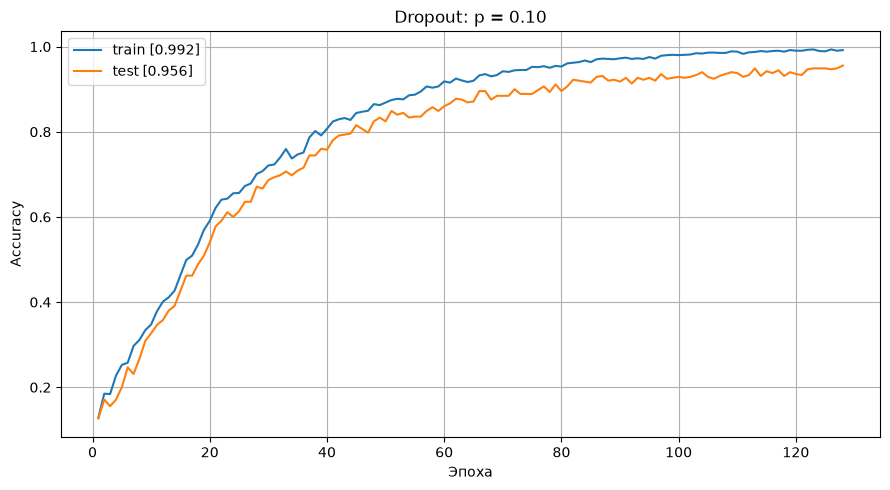

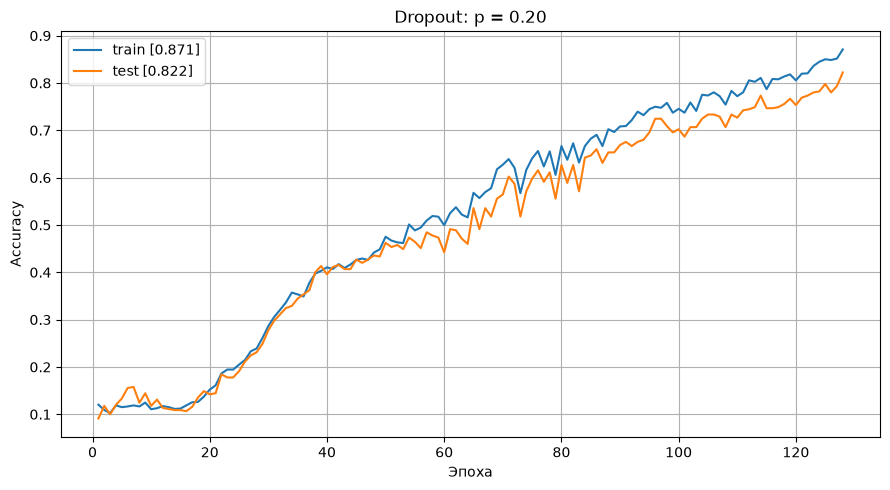

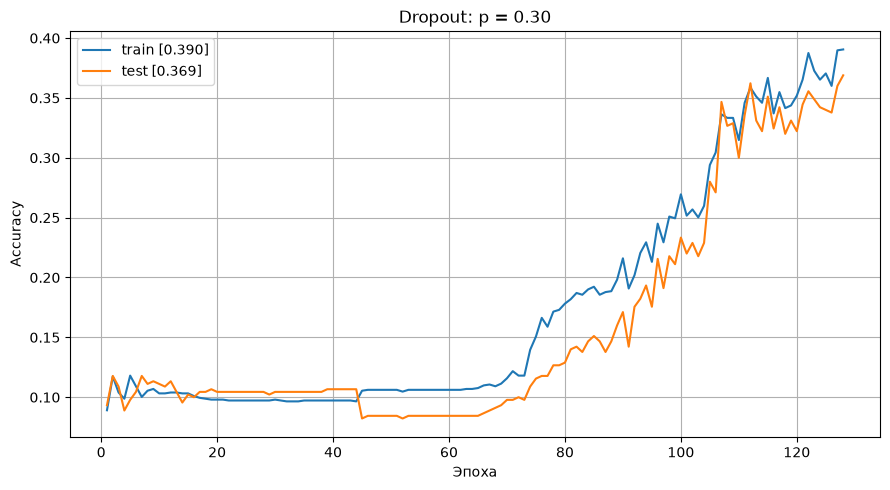

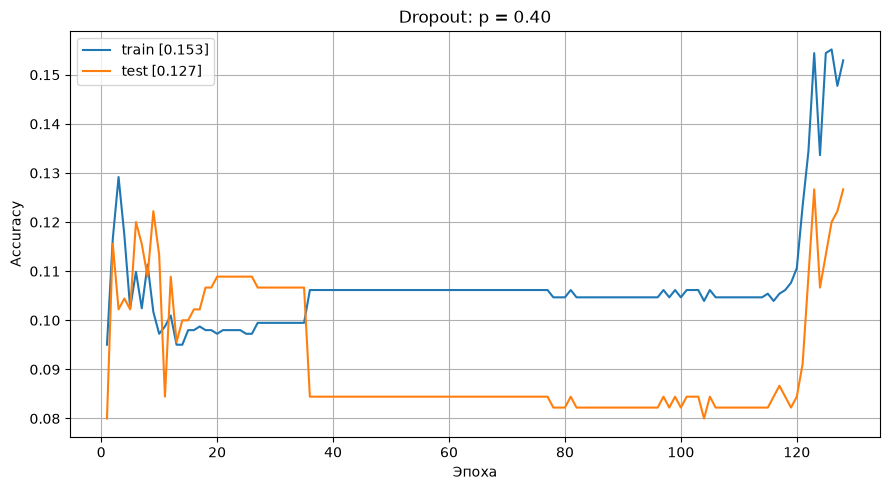

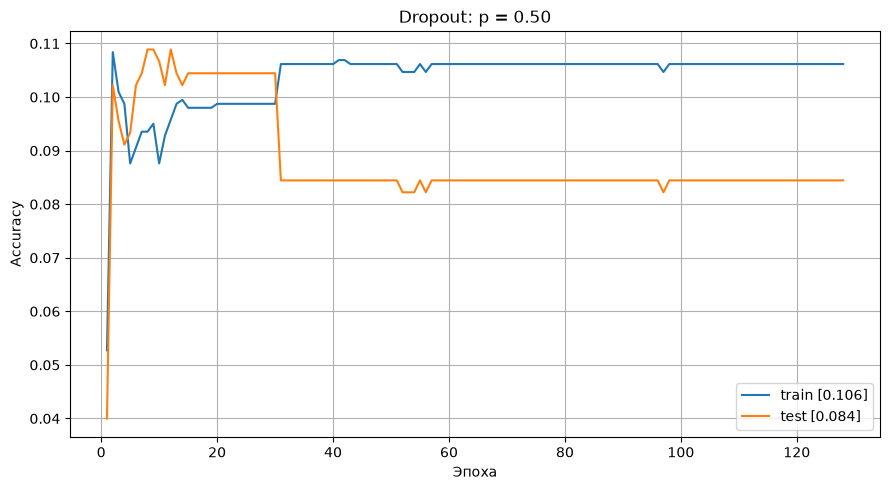

In [79]:
p_vars = np.linspace(0.1, 0.5, num=5)

np.random.seed(42)

network = make_network_with_dropout(input_size, hidden_layers_size, output_size, 7, ReLU)
initialize_network(network, "Kaiming")
initial_weights = get_weights(network).copy()

best_p = 0.1
best_acc = 0

for p in p_vars:
    inference = False
    network = make_network_with_dropout(input_size, hidden_layers_size, output_size, 7, ReLU, p)
    weights = initial_weights.copy()
    
    cb = Callback(network, X_train, y_train, X_test, y_test, print=False)

    res = Adam(
        compute_loss_grad, weights,  
        args=[network, X_train, y_train],
        n_iter = 128,
        lr = 1e-3,
        beta_1 = 0.9,
        beta_2 = 0.999,
        batch_size=32,
        jac=True,
        callback=cb.call
    )


    if cb.test_acc[-1] > best_acc:
        best_acc = cb.test_acc[-1]
        best_p = p

    # plot by chatgpt

    epochs = np.arange(1, len(cb.train_acc) + 1)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(
        epochs, cb.train_acc,
        label=f"train [{cb.train_acc[-1]:.3f}]",
    )
    ax.plot(
        epochs, cb.test_acc,
        label=f"test [{cb.test_acc[-1]:.3f}]",
    )

    ax.set_title(f"Dropout: p = {p:.2f}")
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Accuracy")
    ax.grid(True)
    ax.legend()
    fig.tight_layout()
    plt.show()

Dropout, p=0.10: train=0.9718, test=0.9378, эпох=128
Без dropout: train=1.0000, test=0.9489, эпох=128


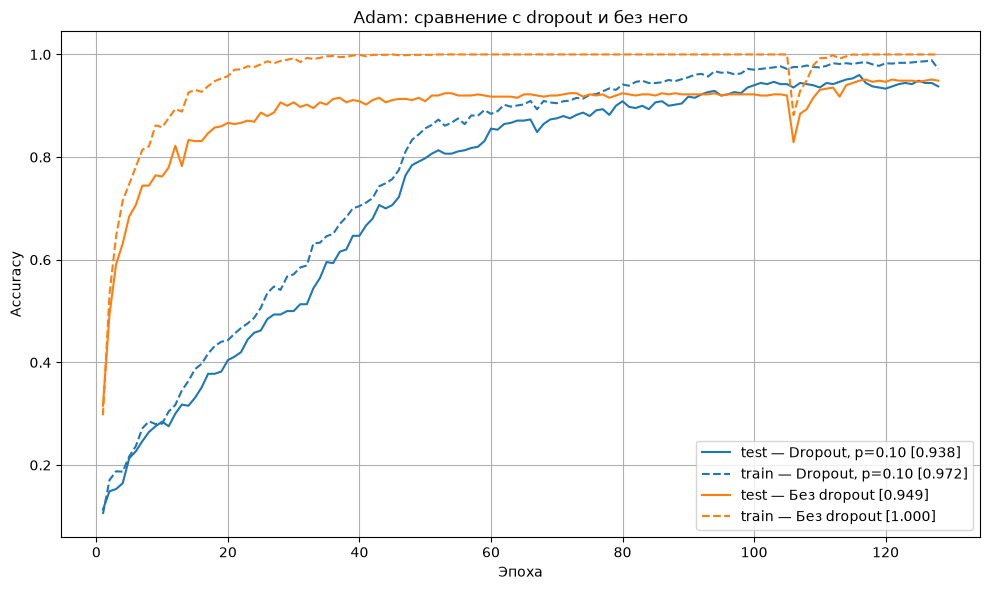

Dropout, p=0.10: train=0.9926, test=0.9533, эпох=128
Без dropout: train=1.0000, test=0.9489, эпох=128


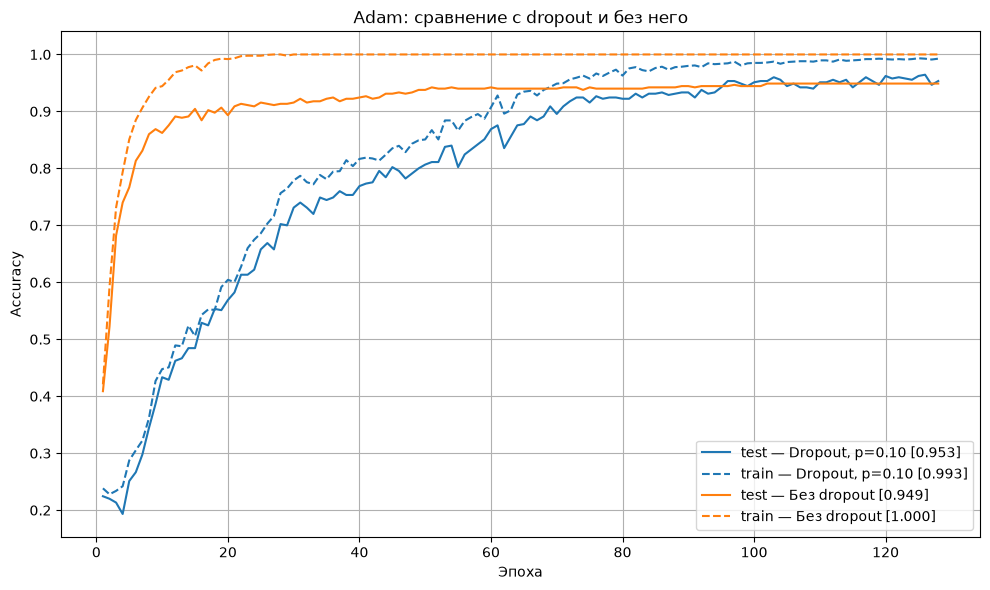

Dropout, p=0.10: train=0.9941, test=0.9533, эпох=128
Без dropout: train=1.0000, test=0.9267, эпох=128


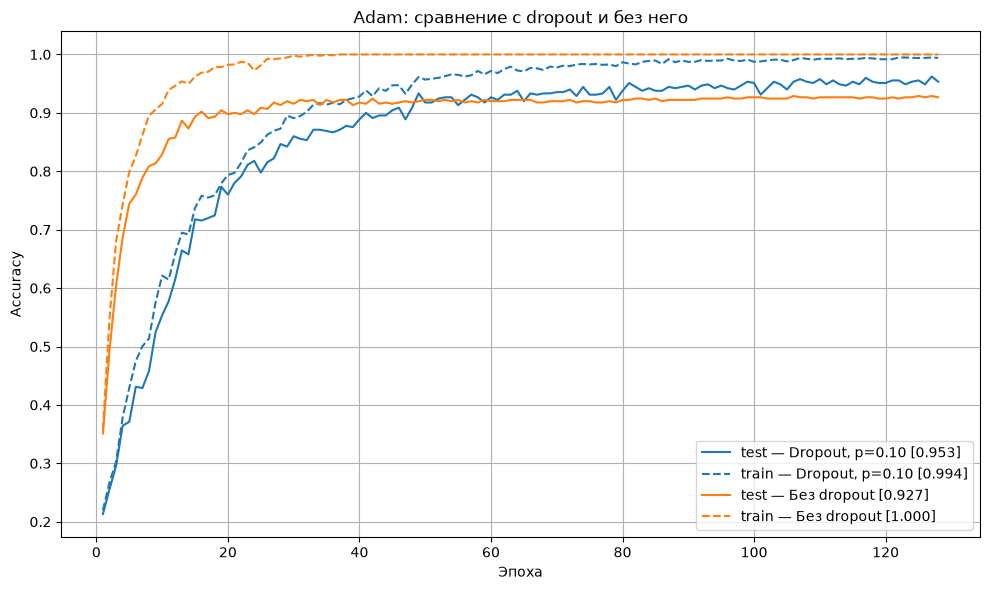

Dropout, p=0.10: train=0.9933, test=0.9533, эпох=128
Без dropout: train=1.0000, test=0.9311, эпох=128


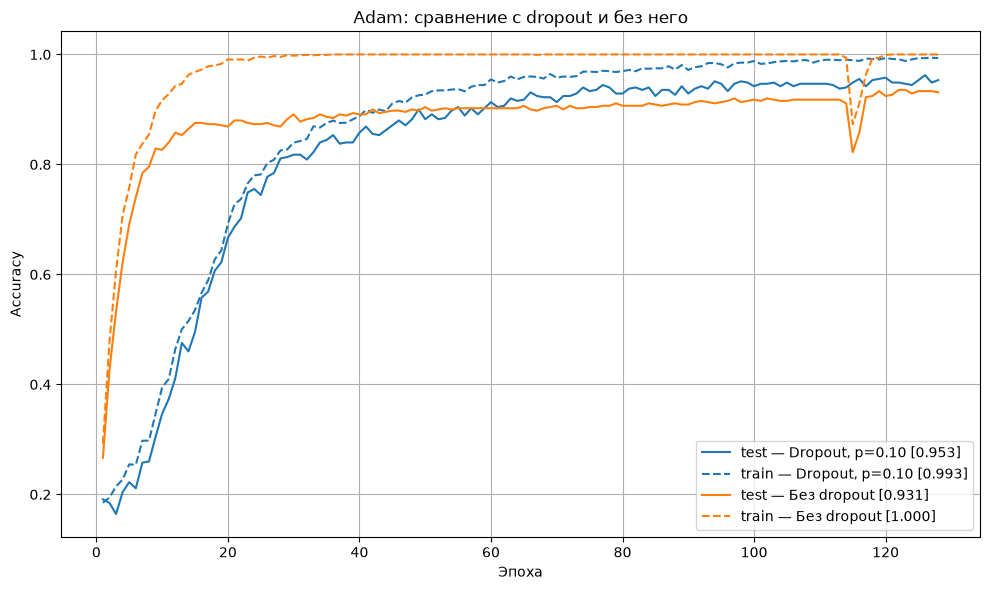

Dropout, p=0.10: train=0.9918, test=0.9600, эпох=128
Без dropout: train=1.0000, test=0.9444, эпох=128


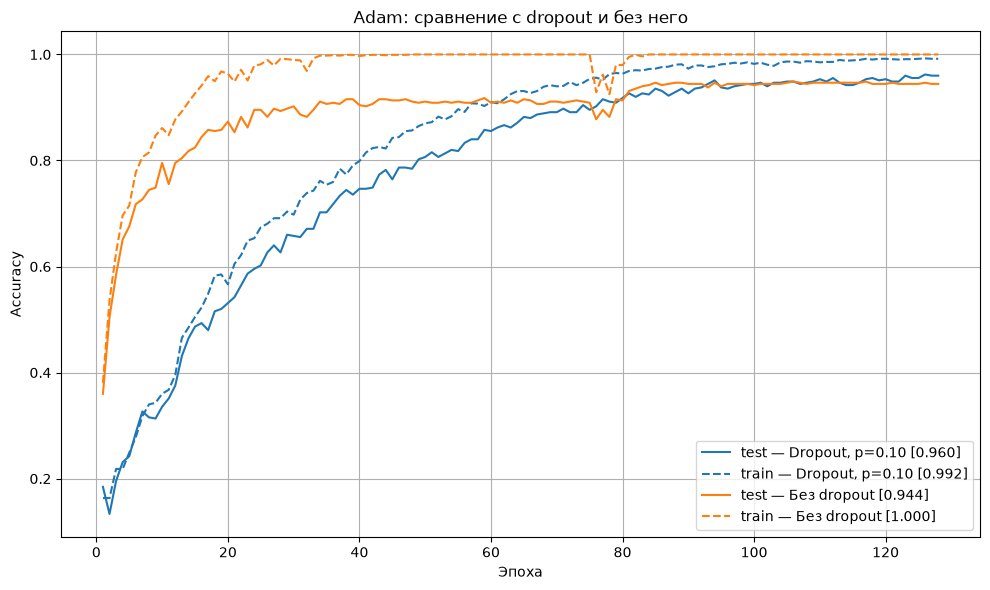

In [80]:
for test in range(0, 5):
    np.random.seed(239 + test)

    dropout_network = make_network_with_dropout(input_size, hidden_layers_size, output_size, 7, ReLU, best_p)
    initialize_network(dropout_network, "Kaiming")
    initial_weights = get_weights(dropout_network)
    dropout_weights = initial_weights.copy()
    dropout_cb = Callback(dropout_network, X_train, y_train, X_test, y_test, print=False)
    res_dropout = Adam(
        compute_loss_grad, dropout_weights,  
        args=[dropout_network, X_train, y_train],
        n_iter = 128,
        lr = 1e-3,
        beta_1 = 0.9,
        beta_2 = 0.999,
        batch_size=32,
        jac=True,
        callback=dropout_cb.call
    )

    network = make_network(input_size, hidden_layers_size, output_size, 7, ReLU)
    weights = initial_weights.copy()
    cb = Callback(network, X_train, y_train, X_test, y_test, print=False)
    res = Adam(
        compute_loss_grad, weights,  
        args=[network, X_train, y_train],
        n_iter = 128,
        lr = 1e-3,
        beta_1 = 0.9,
        beta_2 = 0.999,
        batch_size=32,
        jac=True,
        callback=cb.call
    )

    # plot by chatgpt
    fig, ax = plt.subplots(figsize=(10, 6))

    for name, history in [
        (f"Dropout, p={best_p:.2f}", dropout_cb),
        ("Без dropout", cb),
    ]:
        epochs = np.arange(1, len(history.train_acc) + 1)

        line, = ax.plot(
            epochs, history.test_acc,
            label=f"test — {name} [{history.test_acc[-1]:.3f}]",
        )
        ax.plot(
            epochs, history.train_acc,
            color=line.get_color(),
            linestyle="--",
            label=f"train — {name} [{history.train_acc[-1]:.3f}]",
        )

        print(
            f"{name}: "
            f"train={history.train_acc[-1]:.4f}, "
            f"test={history.test_acc[-1]:.4f}, "
            f"эпох={len(history.train_acc)}"
        )

    ax.set_title("Adam: сравнение с dropout и без него")
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Accuracy")
    ax.grid(True)
    ax.legend()
    fig.tight_layout()
    plt.show()

**Выводы:** по графикам видно, что благодаря dropout у нас есть прирост в районе 0.01. Так же видно, что введение таких слоев замедляет обучение нейросети, и они дольше выходят на плато. При этом на train не было достигнуто единичной accuracy (при лучшей test accuracy), что косвенно подтверждает, что dropout помогает бороться с переобучением. Видно, что слишком большие p не дают модели обучиться, так что надо искать баланс.

### `BatchNormalization (1 балл)`

Реализуйте слой `BatchNormalization`. Сравните обучение сети из большого числа слоёв при использовании `BatchNormalization` и без его использования. Сделайте выводы.

Из первого задания:

$ \gamma $ и $ \delta $ для одного признака:

$$ \nabla_{\delta} \mathcal{L}
=
\mathbf{1}^T \nabla_{y} \mathcal{L} 
=
\sum\limits_{i = 1}^{n} \frac{\partial \mathcal{L}}{\partial y_i} $$

$$
\nabla_{\gamma} \mathcal{L}
=
\tilde{y}^T \nabla_{y} \mathcal{L}
=
\frac{\sum\limits_{i = 1}^{n} (X_{i} - \mu) \frac{\partial \mathcal{L}}{\partial y_i}}{\sqrt{\sigma^2 + \varepsilon}}
$$

Градиент для одного признака:

$$
\nabla_{X_j} \mathcal{L}
=
\frac{\gamma}{\sqrt{\sigma_j^2 + \varepsilon}}
\left(
\left( I - \frac{1}{n} ( \mathbf{1} \cdot \mathbf{1}^T ) \right)
-
\frac{1}{n} \tilde{y_j} \tilde{y_j}^T
\right)
\nabla_{y} \mathcal{L}
$$

$$
\frac{1}{n} \tilde{y_j} \tilde{y_j}^T G^y
=
\frac{1}{n} \tilde{y_j} \left( \sum\limits_i \tilde{y_{ji}} G^y_i \right)
$$

То есть $ j $-й столбец умножается просто на $ \sum\limits_i \tilde{y_{ji}} G^y_i $, а это просто сумма в $ (y_j * G_y) $


In [81]:
class BatchNormalization:
    def __init__(self, num_units, momentum=0.1):
        self.gamma = np.ones((1, num_units))
        self.delta = np.zeros((1, num_units))
        self.eps = 1e-8
        self.params = [self.gamma, self.delta]

        self.momentum = momentum

        self.total_mu = np.zeros((1, num_units))
        self.total_sigma_sq = np.ones((1, num_units))

    def forward(self, input):
        if not inference:
            batch_size, num_units = input.shape

            self.input = input

            self.mu = np.sum(input, axis = 0) / batch_size
            sigma_sq = np.sum((input - self.mu) ** 2, axis=0) / batch_size

            self.sigma = np.sqrt(sigma_sq + self.eps)

            self.total_mu = (1 - self.momentum) * self.total_mu + self.momentum * self.mu
            self.total_sigma_sq = (1 - self.momentum) * self.total_sigma_sq + self.momentum * sigma_sq

            self.std = (input - self.mu) / self.sigma
        else:
            self.std = (input - self.total_mu) / np.sqrt(self.total_sigma_sq + self.eps)
        
        return self.gamma * self.std + self.delta
        
    def backward(self, grad_output):
        """
        grad_output shape: [batch, num_units]
        output 1 shape: [batch, num_units]
        output 2: []
        """

        gamma_g = np.sum(self.std * grad_output, axis=0)
        delta_g = np.sum(grad_output, axis=0)

        # grad_input = np.zeros_like(grad_output)
        # I = np.eye(batch_size)
        # J = np.ones((batch_size, batch_size))
        # for j in range(num_units):
        #     std_j = self.std[:, j]
        #     A = I - J / batch_size - np.outer(std_j, std_j) / batch_size
        #     grad_input[:, j] = grad_output[:, j] @ A
        # grad_input *= self.gamma / self.sigma

        if not inference:
            batch_size, num_units = self.input.shape
            grad_input = (
                grad_output 
                - np.sum(grad_output, axis=0, keepdims=True) / batch_size 
                - self.std * np.sum(self.std * grad_output, axis=0, keepdims=True) / batch_size
            ) * self.gamma / self.sigma
        else:
            grad_input = grad_output * self.gamma / np.sqrt(
                self.total_sigma_sq + self.eps
            )
        
        return grad_input, np.r_[gamma_g, delta_g]
    
    def __repr__(self):
        return 'BatchNormalization()'

In [82]:
def make_network_with_batch_norm(input_size, hidden_layers_size, output_size, n_layers=3, activation_class=ReLU):
    network = []

    for layer_idx in range(n_layers):
        # Compute sizes of current linear layer
        layer_in = input_size if layer_idx == 0 else hidden_layers_size
        layer_out = output_size if layer_idx == n_layers - 1 else hidden_layers_size
        
        # Add linear layer to the network
        network.append(Dense(layer_in, layer_out))

        # Add activation after each layer except the last one
        if layer_idx != n_layers - 1:
            network.append(BatchNormalization(hidden_layers_size))
            network.append(activation_class())

    # Add LogSoftmax layer to the network
    network.append(LogSoftmax())

    return network

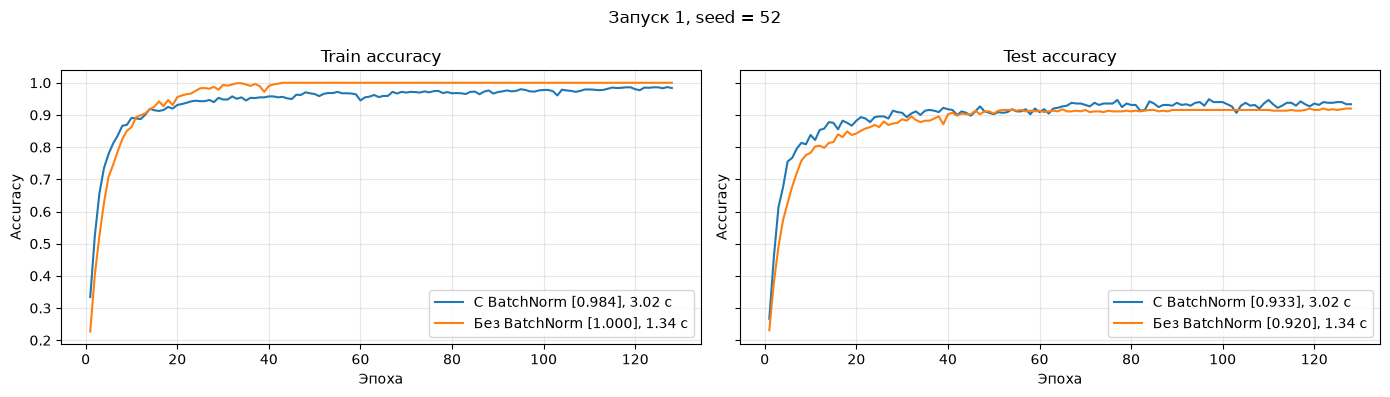

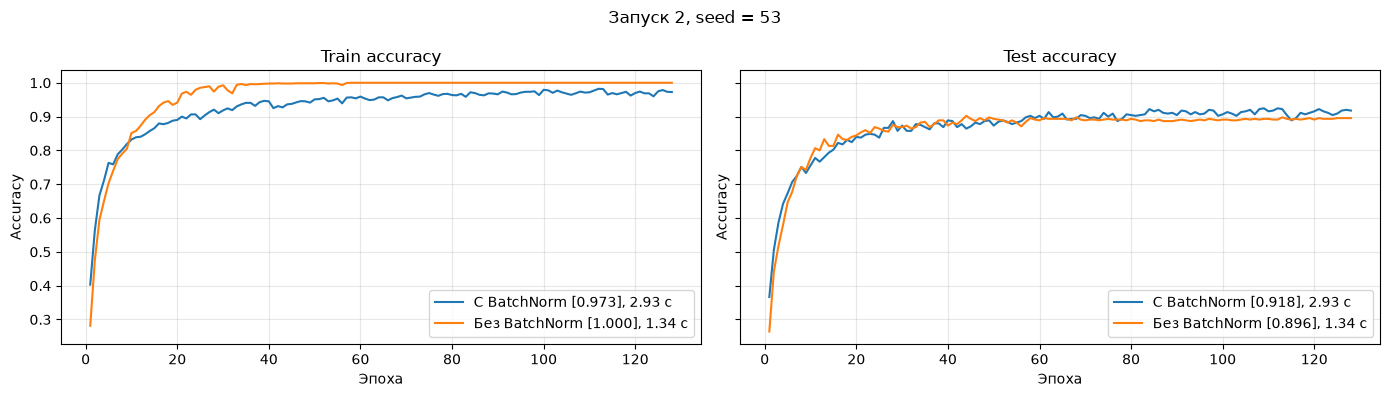

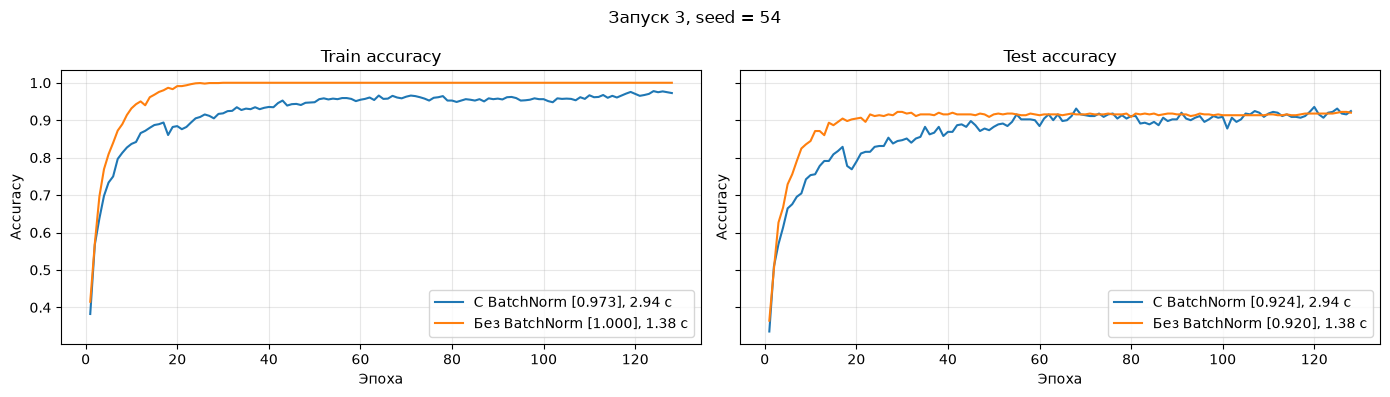

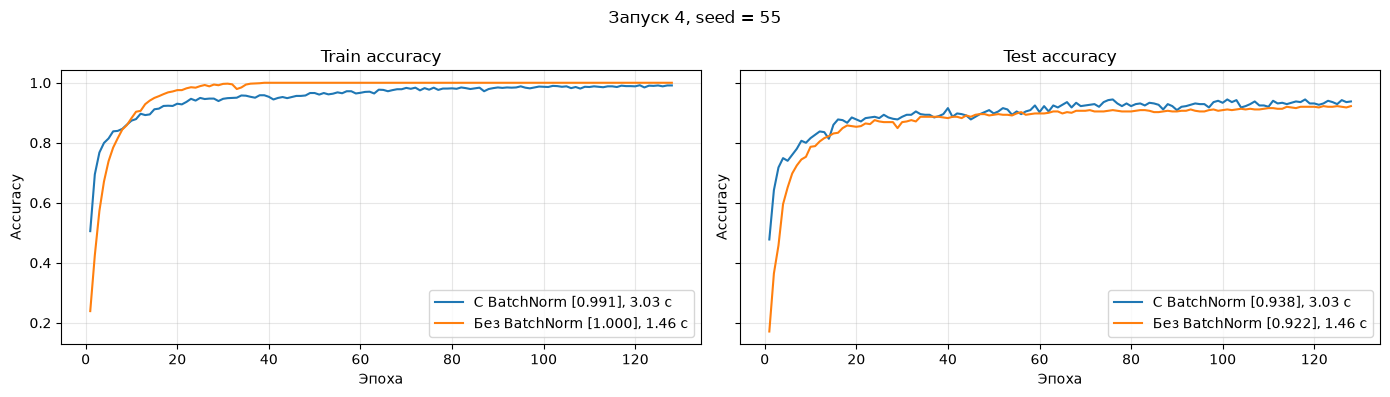

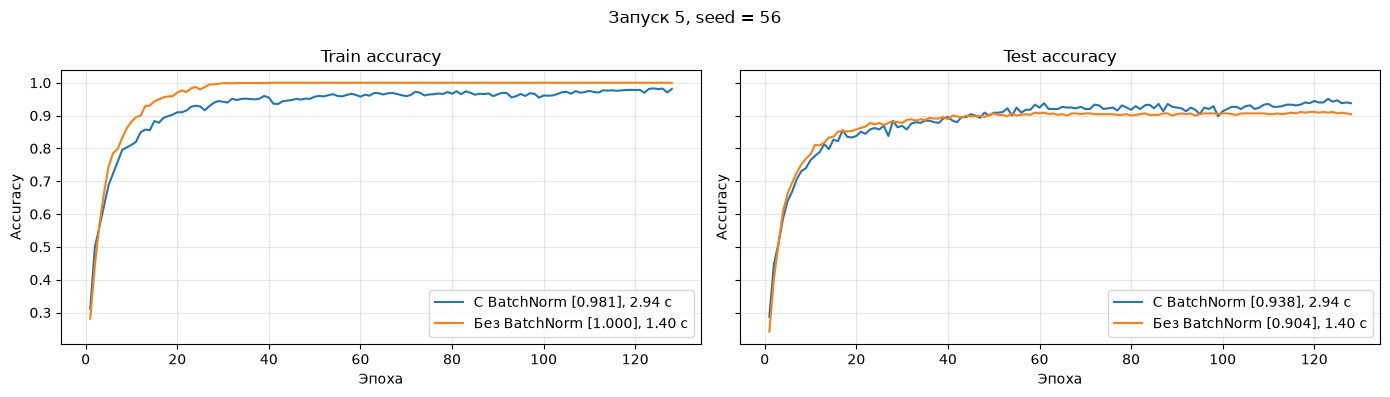

In [83]:
# 5 раз запустим и то, и то, посмотрим на графики

for test in range(5):
    np.random.seed(52 + test)
    inference = False

    batch_norm_network = make_network_with_batch_norm(input_size, hidden_layers_size, output_size, 8, ReLU)
    initialize_network(batch_norm_network, "Kaiming")
    batch_norm_weights = get_weights(batch_norm_network)
    batch_norm_cb = Callback(batch_norm_network, X_train, y_train, X_test, y_test, print=False)

    start = perf_counter()
    res_batch_norm = Adam(
        compute_loss_grad, batch_norm_weights,  
        args=[batch_norm_network, X_train, y_train],
        n_iter = 128,
        lr = 1e-3,
        beta_1 = 0.9,
        beta_2 = 0.999,
        batch_size=32,
        jac=True,
        callback=batch_norm_cb.call
    )
    elapsed_batch_norm = perf_counter() - start

    network = make_network(input_size, hidden_layers_size, output_size, 8, ReLU)
    initialize_network(network, "Kaiming")
    weights = get_weights(network)
    cb = Callback(network, X_train, y_train, X_test, y_test, print=False)

    start = perf_counter()
    res = Adam(
        compute_loss_grad, weights,  
        args=[network, X_train, y_train],
        n_iter = 128,
        lr = 1e-3,
        beta_1 = 0.9,
        beta_2 = 0.999,
        batch_size=32,
        jac=True,
        callback=cb.call
    )
    elapsed_default = perf_counter() - start

    # plot by chatgpt
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

    for ax, metric, title in zip(
        axes,
        ["train_acc", "test_acc"],
        ["Train accuracy", "Test accuracy"],
    ):
        bn_values = getattr(batch_norm_cb, metric)
        values = getattr(cb, metric)

        ax.plot(
            np.arange(1, len(bn_values) + 1),
            bn_values,
            label=f"С BatchNorm [{bn_values[-1]:.3f}], {elapsed_batch_norm:.2f} с",
        )
        ax.plot(
            np.arange(1, len(values) + 1),
            values,
            label=f"Без BatchNorm [{values[-1]:.3f}], {elapsed_default:.2f} с",
        )

        ax.set_title(title)
        ax.set_xlabel("Эпоха")
        ax.set_ylabel("Accuracy")
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(f"Запуск {test + 1}, seed = {52 + test}")
    fig.tight_layout()
    plt.show()

**Выводы:** на основе целых пяти тестов, можно полагать, что использование batch normalization дает прирост к итоговому accuracy. Однако за это приходится платить временем обучения. К тому же видно, что график accuracy у batch normalization сильно скачет.